In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 
import scipy

# Loading The dataset

In [2]:
train_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/trained/'
not_trained_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/not trained/'
AI_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/AI/trained'
AI_2arm_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/AI/2arm/trained'
bl_4arm_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/base-line/4 arm'
bl_2arm_path = 'D:/University/University of Tehran/MSc/Thesis/task/data/base-line/2 arm'
all_trained_4arm_df = []
all_not_trained_4arm_df = []
all_trained_2arm_df = []
all_not_trained_2arm_df = []
all_AI_4arm_df = []
all_AI_2arm_df = []
all_bl_4arm_df = []
all_bl_2arm_df = []
for sub in range(1, 46):
    main_file = '4 arm/subject' + str(sub) + '.csv'
    file_2arm = '2 arm/subject' + str(sub) + '_2arm.csv'
    all_trained_4arm_df.append(pd.read_csv(train_path + main_file))
    all_trained_2arm_df.append(pd.read_csv(train_path + file_2arm))
    
for sub in range(1, 46):
    main_file = '4 arm/subject' + str(sub) + '.csv'
    file_2arm = '2 arm/subject' + str(sub) + '_2arm.csv'
    all_not_trained_4arm_df.append(pd.read_csv(not_trained_path + main_file))
    all_not_trained_2arm_df.append(pd.read_csv(not_trained_path + file_2arm))


for sub in range(1, 21):
    main_file = '/subject' + str(sub) + '.csv'
    file_2arm = '/subject' + str(sub) + '_2arm.csv'
    all_AI_4arm_df.append(pd.read_csv(AI_path + main_file))
    all_AI_2arm_df.append(pd.read_csv(AI_2arm_path + file_2arm))
    
for sub in range(1, 41):
    main_file = '/subject' + str(sub) + '.csv'
    file_2arm = '/subject' + str(sub) + '_2arm.csv'
    all_bl_4arm_df.append(pd.read_csv(bl_4arm_path + main_file))
    all_bl_2arm_df.append(pd.read_csv(bl_2arm_path + file_2arm))

In [3]:
all_sub_df = all_trained_4arm_df + all_not_trained_4arm_df + all_bl_4arm_df
all_sub_2arm_df = all_trained_2arm_df + all_not_trained_2arm_df + all_bl_2arm_df
g1_len = len(all_trained_4arm_df)
g2_len = len(all_not_trained_4arm_df)
g3_len = len(all_bl_4arm_df)
g1 = 'SoLI '
g2 = 'SoLU'
g3 = 'Solo'

# Rewards

In [4]:
def trial_reward(list_subs):
    all_rewards = []
    for sub in list_subs:
        outcome = sub['outcome']
        outcome = outcome.replace('win', 1)
        outcome = outcome.replace('lose', 0)
        all_rewards.append(np.array(outcome.copy()))
    return np.array(all_rewards)

In [5]:
trained_rewards = trial_reward(all_trained_4arm_df)
not_trained_rewards = trial_reward(all_not_trained_4arm_df)
bl_rewards = trial_reward(all_bl_4arm_df)

In [6]:
def mov_avg(data, ws):
    moving_averages = []
    for i in range(len(data)):
        if i < ws - 1:
            moving_averages.append(data[i])
        else:
            window = data[i - ws + 1:i + 1]
            window_average = sum(window) / ws
            moving_averages.append(window_average)

    return moving_averages

In [7]:
mean_trained_rewards = np.mean(trained_rewards, axis=0)
sem_trained_rewards = scipy.stats.sem(trained_rewards, axis=0)
trained_rewards_cl = sem_trained_rewards * scipy.stats.t.ppf((1 + 0.95) / 2., trained_rewards.shape[0] - 1)
trained_x = np.arange(mean_trained_rewards.shape[0])

mean_not_trained_rewards = np.mean(not_trained_rewards, axis=0)
sem_not_trained_rewards = scipy.stats.sem(not_trained_rewards, axis=0)
not_trained_rewards_cl = sem_not_trained_rewards * scipy.stats.t.ppf((1 + 0.95) / 2., not_trained_rewards.shape[0] - 1)
not_trained_x = np.arange(mean_trained_rewards.shape[0])

mean_bl_rewards = np.mean(bl_rewards, axis=0)
sem_bl_rewards = scipy.stats.sem(bl_rewards, axis=0)
bl_rewards_cl = sem_bl_rewards * scipy.stats.t.ppf((1 + 0.95) / 2., bl_rewards.shape[0] - 1)
bl_x = np.arange(mean_trained_rewards.shape[0])

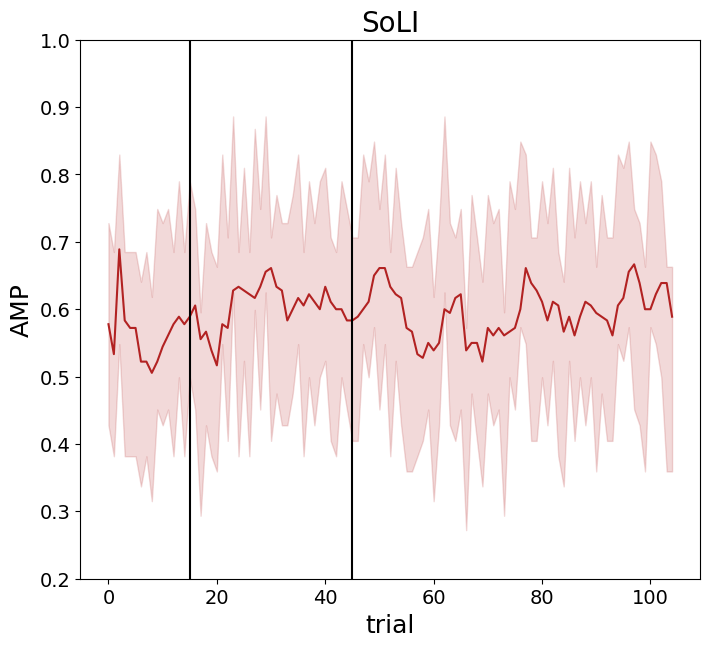

In [8]:
# Solo olivedrab,
# SoLU royalblue,
# SoLI firebrick 

fig, axs = plt.subplots(1, 1, sharey='all', figsize=(8, 7))

av_trained_rewards = mov_avg(mean_trained_rewards, 4)
axs.plot(trained_x, av_trained_rewards, color='firebrick')
axs.fill_between(trained_x, mean_trained_rewards - trained_rewards_cl, mean_trained_rewards + trained_rewards_cl, color='firebrick', alpha=0.17)
axs.axvline(x=15, color='black')
axs.axvline(x=45, color='black')
axs.set_ylim([0.2, 1])
axs.set_title('SoLI', fontsize=20)
axs.set_xlabel('trial', fontsize=18)
axs.set_ylabel('AMP', fontsize=18)
axs.tick_params(axis='both', labelsize=14)
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/soli-rew.svg')

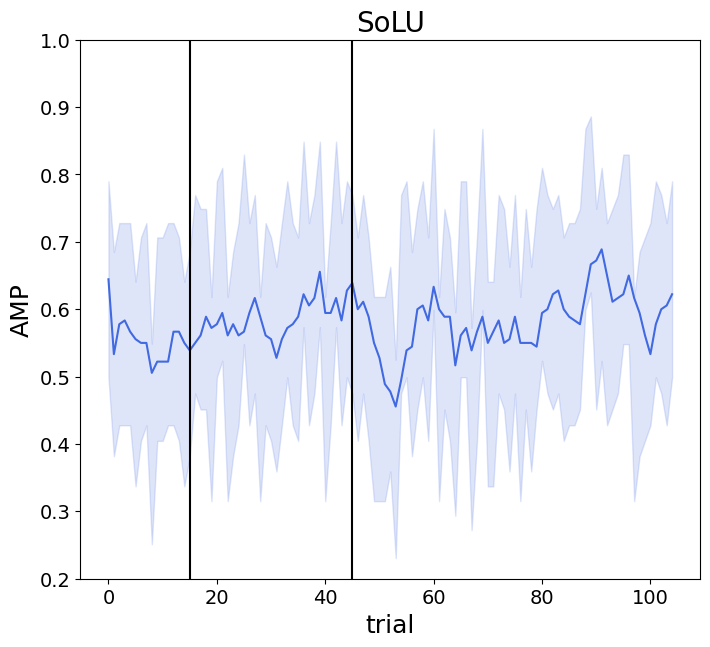

In [9]:
fig, axs = plt.subplots(1, 1, sharey='all', figsize=(8, 7))

av_not_trained_rewards = mov_avg(mean_not_trained_rewards, 4)
axs.plot(not_trained_x, av_not_trained_rewards, color='royalblue')
axs.fill_between(not_trained_x, mean_not_trained_rewards - not_trained_rewards_cl, mean_not_trained_rewards + not_trained_rewards_cl, color='royalblue', alpha=0.17)
axs.axvline(x=15, color='black')
axs.axvline(x=45, color='black')
axs.set_ylim([0.2, 1])
axs.set_title('SoLU',fontsize=20)
axs.set_xlabel('trial', fontsize=18)
axs.set_ylabel('AMP', fontsize=18)
axs.tick_params(axis='both', labelsize=14)
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/solu-rew.svg')

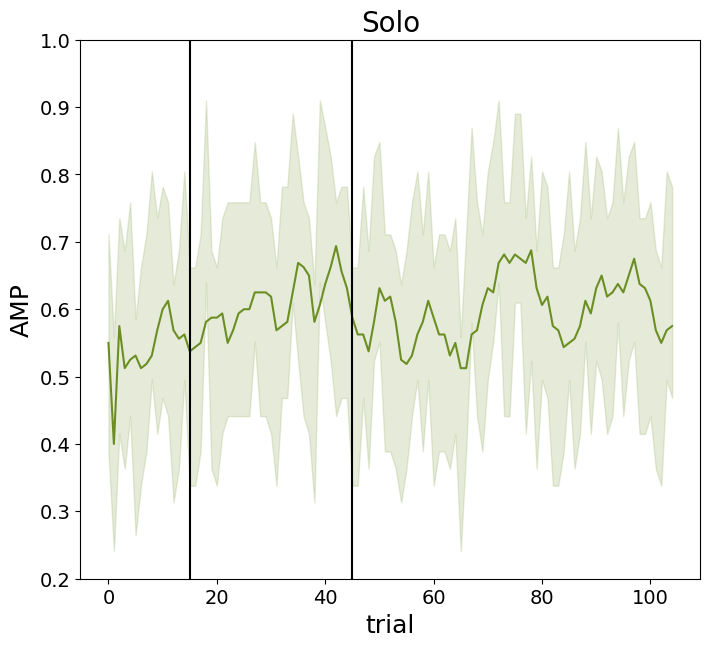

In [10]:
fig, axs = plt.subplots(1, 1, sharey='all', figsize=(8, 7))

av_bl_rewards = mov_avg(mean_bl_rewards, 4)
axs.plot(bl_x, av_bl_rewards, color='olivedrab')
axs.fill_between(bl_x, mean_bl_rewards - bl_rewards_cl, mean_bl_rewards + bl_rewards_cl, color='olivedrab', alpha=0.17)
axs.axvline(x=15, color='black')
axs.axvline(x=45, color='black')
axs.set_ylim([0.2, 1])
axs.set_title('Solo', fontsize=20)
axs.set_xlabel('trial', fontsize=18)
axs.set_ylabel('AMP', fontsize=18)
axs.tick_params(axis='both', labelsize=14)
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/solo-rew.svg')

In [11]:
trained_rewards.shape

(45, 105)

In [12]:
from scipy.stats import f_oneway

def is_sig(p):
    if p < 0.05:
        sig = 1
    else:
        sig = 0
    return sig

f, anova_p = f_oneway(trained_rewards, not_trained_rewards, bl_rewards)
anova_sig = []
for p in anova_p:
    anova_sig.append(is_sig(p))
anova_sig = np.array(anova_sig)
anova_sig


array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0,
       0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

# Probability of choosing cards

In [13]:
def sort_choices(all_sub_df):
    all_best_card = []
    all_second_card = []
    all_third_card = []
    all_worst_card = []
    for sub_idx, sub in enumerate(all_sub_df):
        best_card = np.zeros(105)
        second_card = np.zeros(105)
        third_card = np.zeros(105)
        worst_card = np.zeros(105)
        for trial in range(len(all_sub_df[0])):
            cards_type = eval(sub['card probs'][trial])
            best_idx = cards_type.index(0.7)
            second_idx = cards_type.index(0.6)
            third_idx = cards_type.index(0.5)
            worst_idx = cards_type.index(0.4)
            choice = sub['choice'][trial]
            if choice == best_idx:
                best_card[trial] = 1
            elif choice == second_idx: 
                second_card[trial] = 1
            elif choice == third_idx:
                third_card[trial] = 1
            else:
                worst_card[trial] = 1
        all_best_card.append(best_card.copy())
        all_second_card.append(second_card.copy())
        all_third_card.append(third_card.copy())
        all_worst_card.append(worst_card.copy())
    all_best_card = np.array(all_best_card)
    all_second_card = np.array(all_second_card)
    all_third_card = np.array(all_third_card)
    all_worst_card = np.array(all_worst_card)     
    
    return all_best_card, all_second_card, all_third_card, all_worst_card

In [14]:
all_best_card, all_second_card, all_third_card, all_worst_card = sort_choices(all_sub_df)

In [15]:
g3_start = g1_len + g2_len

g1_best_card_mean = np.mean(all_best_card[:g1_len], axis=0)
g1_second_card_mean = np.mean(all_second_card[:g1_len], axis=0)
g1_third_card_mean = np.mean(all_third_card[:g1_len], axis=0)
g1_worst_card_mean = np.mean(all_worst_card[:g1_len], axis=0)

g1_best_card_var = np.var(all_best_card[:g1_len], axis=0)
g1_second_card_var = np.var(all_second_card[:g1_len], axis=0)
g1_third_card_var = np.var(all_third_card[:g1_len], axis=0)
g1_worst_card_var = np.var(all_worst_card[:g1_len], axis=0)


g2_best_card_mean = np.mean(all_best_card[g1_len:g3_start], axis=0)
g2_second_card_mean = np.mean(all_second_card[g1_len:g3_start], axis=0)
g2_third_card_mean = np.mean(all_third_card[g1_len:g3_start], axis=0)
g2_worst_card_mean = np.mean(all_worst_card[g1_len:g3_start], axis=0)

g2_best_card_var = np.var(all_best_card[g1_len:g3_start], axis=0)
g2_second_card_var = np.var(all_second_card[g1_len:g3_start], axis=0)
g2_third_card_var = np.var(all_third_card[g1_len:g3_start], axis=0)
g2_worst_card_var = np.var(all_worst_card[g1_len:g3_start], axis=0)


g3_best_card_mean = np.mean(all_best_card[g3_start:], axis=0)
g3_second_card_mean = np.mean(all_second_card[g3_start:], axis=0)
g3_third_card_mean = np.mean(all_third_card[g3_start:], axis=0)
g3_worst_card_mean = np.mean(all_worst_card[g3_start:], axis=0)

g3_best_card_var = np.var(all_best_card[g3_start:], axis=0)
g3_second_card_var = np.var(all_second_card[g3_start:], axis=0)
g3_third_card_var = np.var(all_third_card[g3_start:], axis=0)
g3_worst_card_var = np.var(all_worst_card[g3_start:], axis=0)

In [16]:
def mov_avg(data, ws):
    moving_averages = []
    for i in range(len(data)):
        if i < ws - 1:
            moving_averages.append(data[i])
        else:
            window = data[i - ws + 1:i + 1]
            window_average = sum(window) / ws
            moving_averages.append(window_average)

    return moving_averages

In [17]:
def smooth_each_block(best_card_mean, second_card_mean, third_card_mean, worst_card_mean, ws):   
    smoothed_best = mov_avg(best_card_mean[:15], ws) + mov_avg(best_card_mean[15:45], ws) + mov_avg(best_card_mean[45:], ws)
    smoothed_second = mov_avg(second_card_mean[:15], ws) + mov_avg(second_card_mean[15:45], ws) + mov_avg(second_card_mean[45:], ws)
    smoothed_third = mov_avg(third_card_mean[:15], ws) + mov_avg(third_card_mean[15:45], ws) + mov_avg(third_card_mean[45:], ws)
    smoothed_worst = mov_avg(worst_card_mean[:15], ws) + mov_avg(worst_card_mean[15:45], ws) + mov_avg(worst_card_mean[45:], ws)
    
    return smoothed_best, smoothed_second, smoothed_third, smoothed_worst

In [18]:
g1_smoothed_best, g1_smoothed_second, g1_smoothed_third, g1_smoothed_worst = smooth_each_block(g1_best_card_mean, g1_second_card_mean, g1_third_card_mean, g1_worst_card_mean, 4)
g2_smoothed_best, g2_smoothed_second, g2_smoothed_third, g2_smoothed_worst = smooth_each_block(g2_best_card_mean, g2_second_card_mean, g2_third_card_mean, g2_worst_card_mean, 4)
g3_smoothed_best, g3_smoothed_second, g3_smoothed_third, g3_smoothed_worst = smooth_each_block(g3_best_card_mean, g3_second_card_mean, g3_third_card_mean, g3_worst_card_mean, 4)

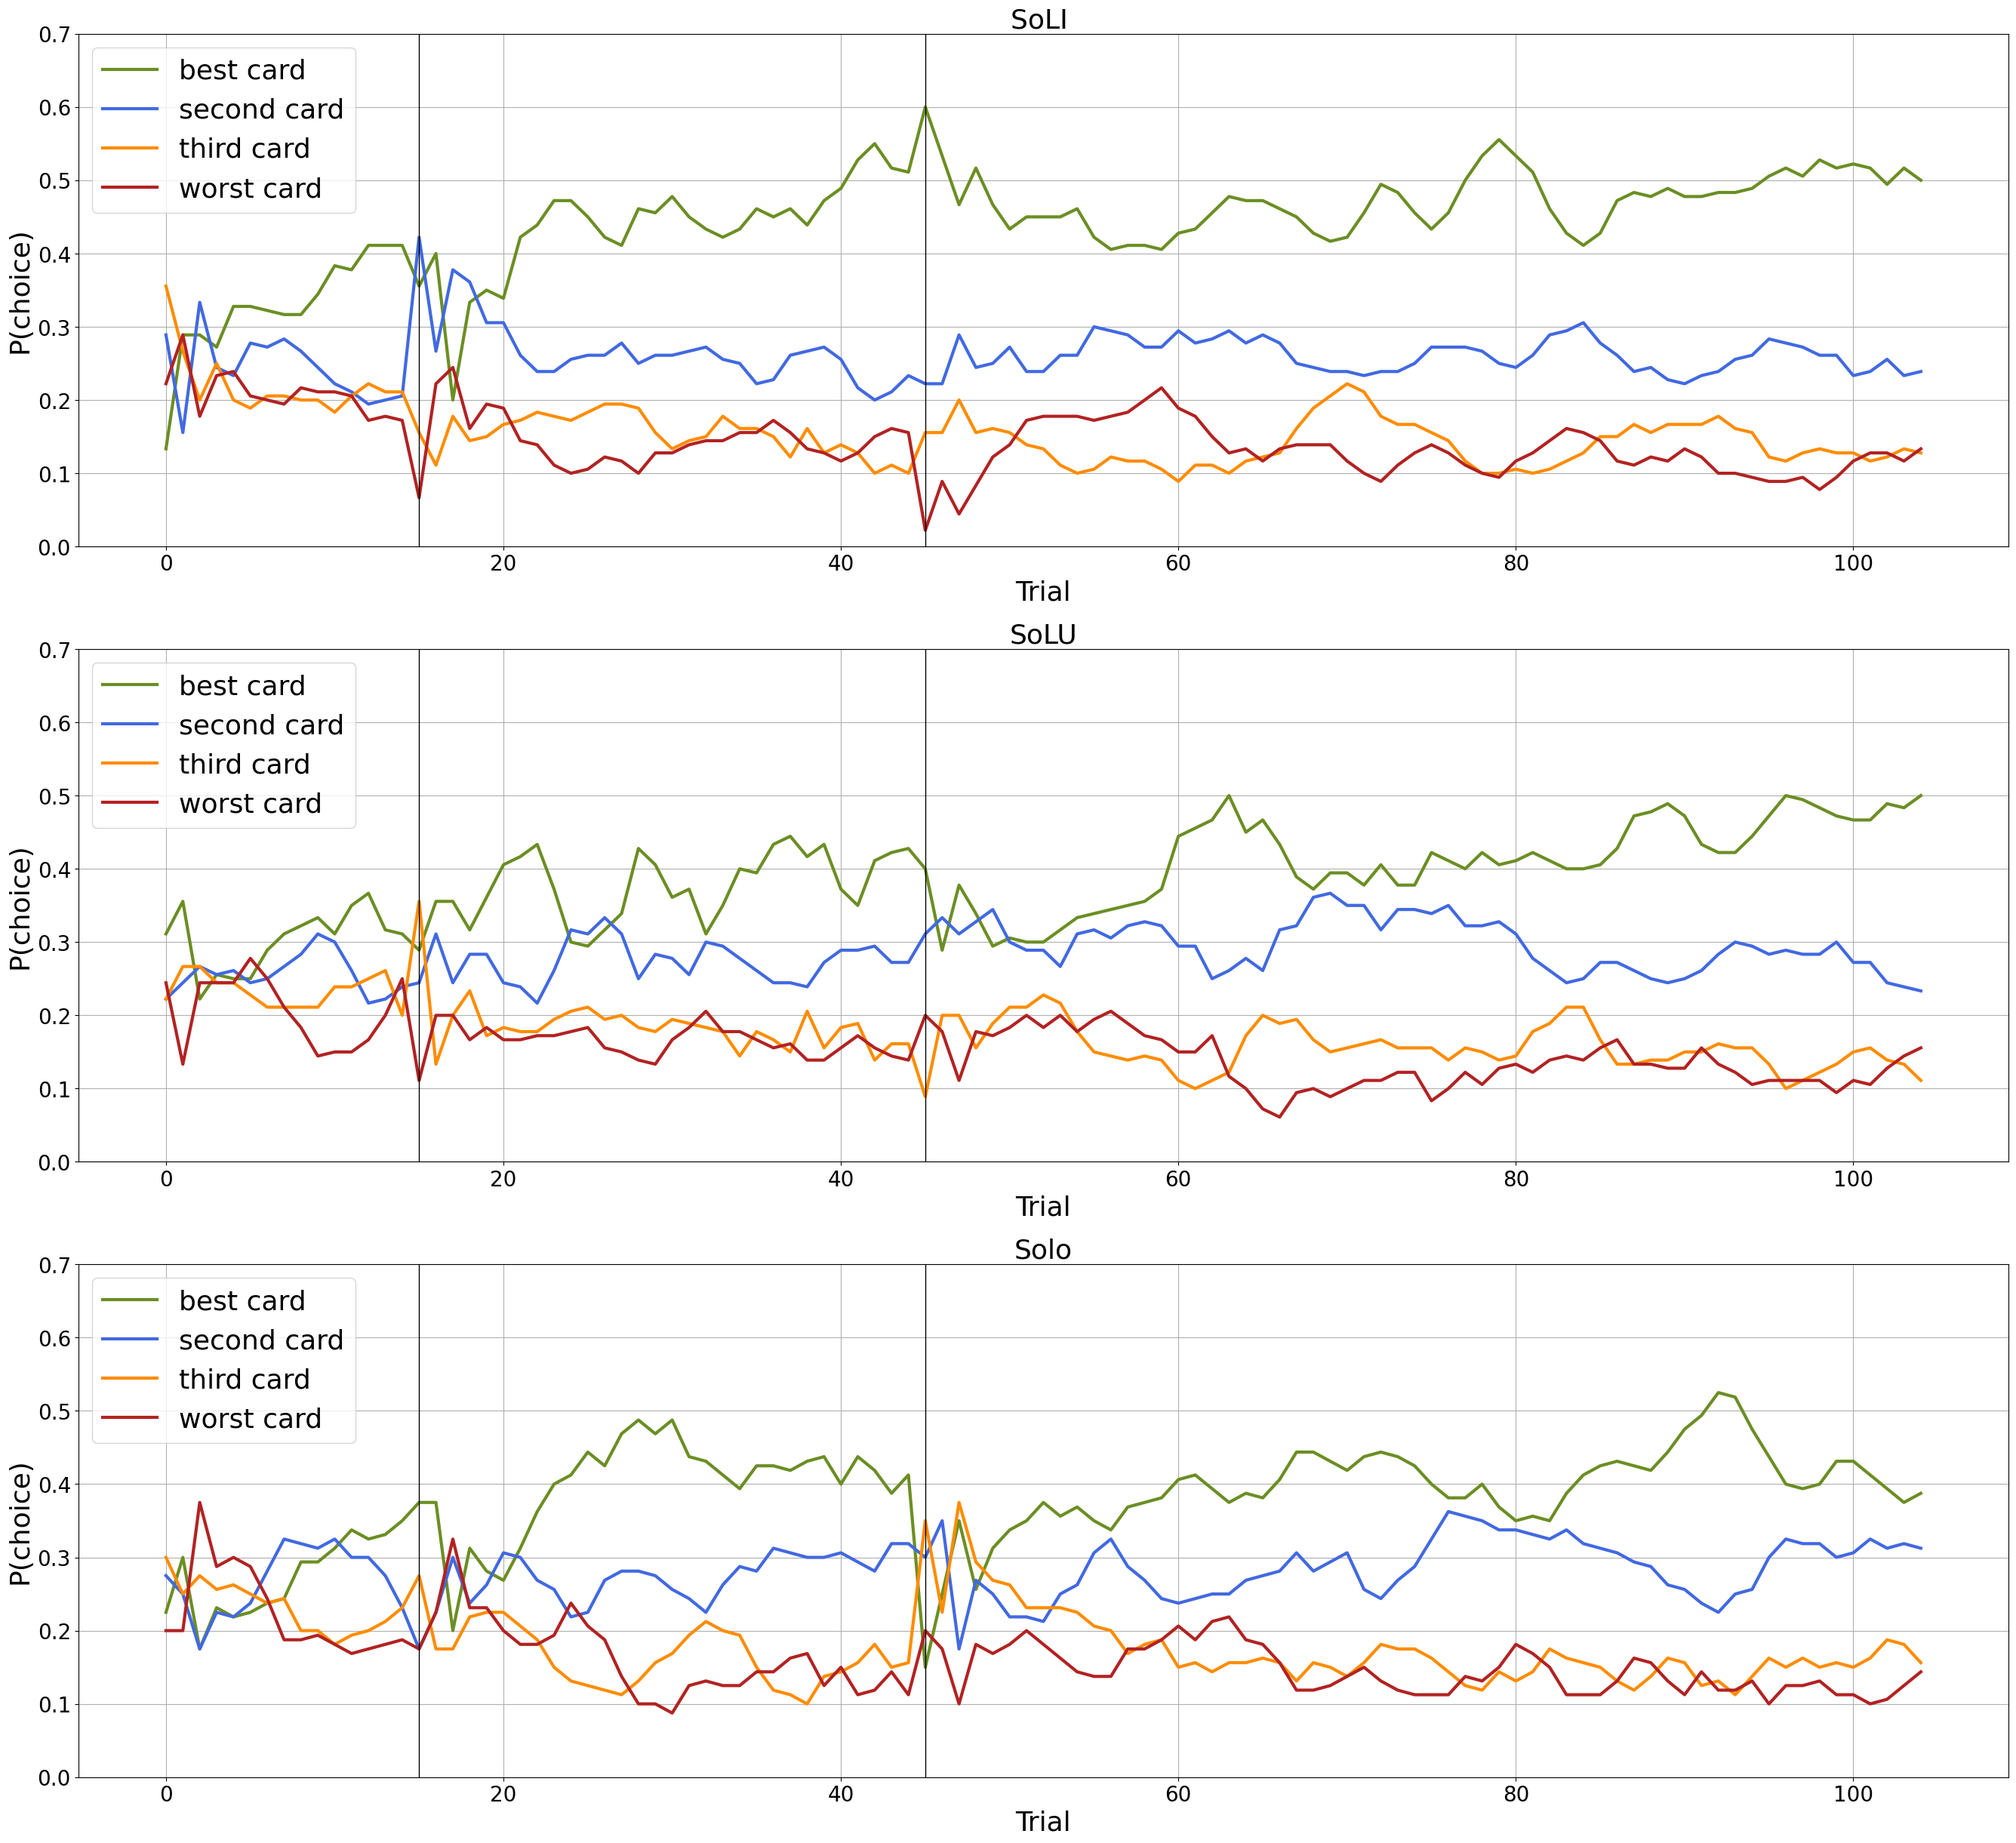

In [57]:
fig, axs = plt.subplots(3, 1, figsize=(33, 30))
# fig.suptitle('Probablity of choosing cards')

fnt_size = 26
lbl_size = 20

axs[0].plot(g1_smoothed_best, color='olivedrab', label='best card', linewidth=3)
axs[0].plot(g1_smoothed_second, color='royalblue', label='second card', linewidth=3)
axs[0].plot(g1_smoothed_third, color='darkorange', label='third card', linewidth=3)
axs[0].plot(g1_smoothed_worst, color='firebrick', label='worst card', linewidth=3)
axs[0].legend()
axs[0].axvline(x=15, color='black', linewidth=1)
axs[0].axvline(x=45, color='black', linewidth=1)
axs[0].set_ylim([0, 0.7])
axs[0].set_title(g1, fontsize=fnt_size)
axs[0].set_xlabel('Trial', fontsize=fnt_size)
axs[0].set_ylabel('P(choice)', fontsize=fnt_size)
axs[0].grid()
axs[0].legend(loc=2, prop={'size': 26})
axs[0].tick_params(axis='both', labelsize=lbl_size)


axs[1].plot(g2_smoothed_best, color='olivedrab', label='best card', linewidth=3)
axs[1].plot(g2_smoothed_second, color='royalblue', label='second card', linewidth=3)
axs[1].plot(g2_smoothed_third, color='darkorange', label='third card', linewidth=3)
axs[1].plot(g2_smoothed_worst, color='firebrick', label='worst card', linewidth=3)
axs[1].legend()
axs[1].axvline(x=15, color='black', linewidth=1)
axs[1].axvline(x=45, color='black', linewidth=1)
axs[1].set_ylim([0, 0.7])
axs[1].grid()
axs[1].set_title(g2, fontsize=fnt_size)
axs[1].set_xlabel('Trial', fontsize=fnt_size)
axs[1].set_ylabel('P(choice)', fontsize=fnt_size)
axs[1].legend(loc=2, prop={'size': 26})
axs[1].tick_params(axis='both', labelsize=lbl_size)


axs[2].plot(g3_smoothed_best, color='olivedrab', label='best card', linewidth=3)
axs[2].plot(g3_smoothed_second, color='royalblue', label='second card', linewidth=3)
axs[2].plot(g3_smoothed_third, color='darkorange', label='third card', linewidth=3)
axs[2].plot(g3_smoothed_worst, color='firebrick', label='worst card', linewidth=3)
# axs[2].plot(g3_smoothed_best, color='darkslategray', label='best card', linewidth=3)
# axs[2].plot(g3_smoothed_second, color='indianred', label='second card', linewidth=3)
# axs[2].plot(g3_smoothed_third, color='darkolivegreen', label='third card', linewidth=3)
# axs[2].plot(g3_smoothed_worst, color='darkgoldenrod', label='worst card', linewidth=3)
axs[2].legend()
axs[2].axvline(x=15, color='black', linewidth=1)
axs[2].axvline(x=45, color='black', linewidth=1)
axs[2].set_ylim([0, 0.7])
axs[2].grid()
axs[2].set_title(g3, fontsize=fnt_size)
axs[2].set_xlabel('Trial', fontsize=fnt_size)
axs[2].set_ylabel('P(choice)', fontsize=fnt_size)
axs[2].legend(loc=2, prop={'size': 26})
axs[2].tick_params(axis='both', labelsize=lbl_size);

# #003f5c -> 'darkslategrey' or 'darkslategray'

# #58508d -> 'darkslateblue' (This is an approximation)

# #8a508f -> 'rebeccapurple' (This is an approximation)

# #ff6361 -> 'tomato'

# Alternative Palette 2: Sophisticated Earth Tones
# Similarly, these are best defined with HEX codes. The closest named colors are:

# #2F4858 -> 'darkslategray'

# #B0413E -> 'firebrick' or 'indianred'

# #687431 -> 'darkolivegreen'

# #D4A25F -> 'peru' or 'darkgoldenrod'


fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/beh.svg')

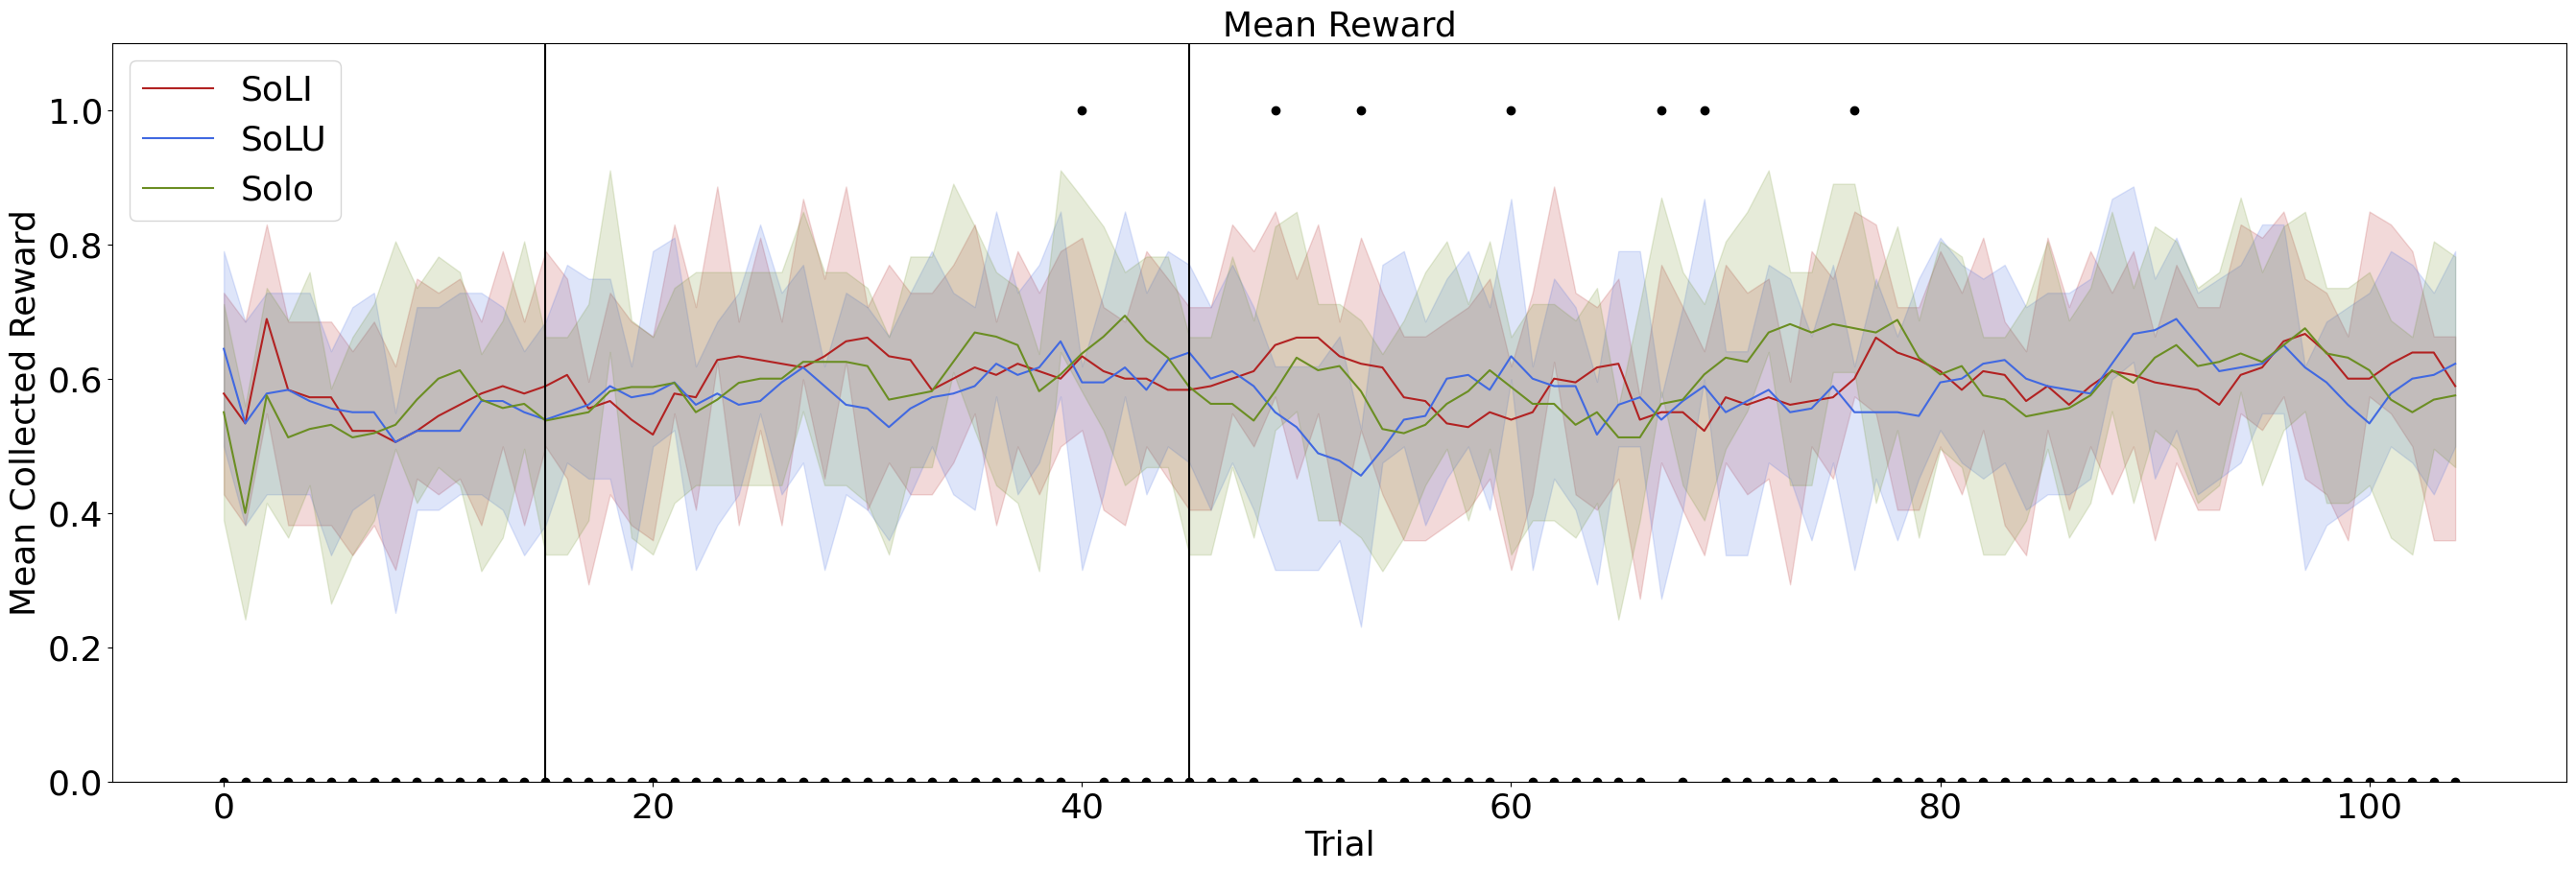

In [54]:
fig, axs = plt.subplots(1, 1, figsize=(33, 10))

x = [i for i in range(105)]

axs.plot(trained_x, av_trained_rewards, color='firebrick', label = 'SoLI')
axs.fill_between(trained_x, mean_trained_rewards - trained_rewards_cl, mean_trained_rewards + trained_rewards_cl, color='firebrick', alpha=0.17)




axs.tick_params(axis='both', labelsize=26)


axs.plot(not_trained_x, av_not_trained_rewards, color='royalblue', label='SoLU')
axs.fill_between(not_trained_x, mean_not_trained_rewards - not_trained_rewards_cl, mean_not_trained_rewards + not_trained_rewards_cl, color='royalblue', alpha=0.17)



axs.tick_params(axis='both', labelsize=26)

av_bl_rewards = mov_avg(mean_bl_rewards, 4)
axs.plot(bl_x, av_bl_rewards, color='olivedrab', label='Solo')
axs.fill_between(bl_x, mean_bl_rewards - bl_rewards_cl, mean_bl_rewards + bl_rewards_cl, color='olivedrab', alpha=0.17)
axs.axvline(x=15, color='black')
axs.axvline(x=45, color='black')

axs.set_title('Mean Reward', fontsize=26)
axs.set_xlabel('Trial', fontsize=26)
axs.set_ylabel('Mean Collected Reward', fontsize=26)
axs.tick_params(axis='both', labelsize=26)

axs.scatter(x, anova_sig, color='black')
axs.set_ylim([0, 1.1])
axs.legend(loc=2, prop={'size': 26})
axs.tick_params(axis='both', labelsize=26)


fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/all-rew.svg')

# axs[0].plot(g1_smoothed_best, color='olivedrab', label='best card', linewidth=3)
# axs[0].plot(g1_smoothed_second, color='royalblue', label='second card', linewidth=3)
# axs[0].plot(g1_smoothed_third, color='darkorange', label='third card', linewidth=3)
# axs[0].plot(g1_smoothed_worst, color='firebrick', label='worst card', linewidth=3)
# axs[0].legend()
# axs[0].axvline(x=15, color='black', linewidth=1)
# axs[0].axvline(x=45, color='black', linewidth=1)
# axs[0].set_ylim([0, 0.7])
# axs[0].set_title(g1, fontsize=20)
# axs[0].set_xlabel('trial', fontsize=18)
# axs[0].set_ylabel('Probability of choice', fontsize=18)
# axs[0].grid()
# axs[0].legend(loc=2, prop={'size': 20})
# axs[0].tick_params(axis='both', labelsize=18)

# Confidence

In [33]:
def get_coloumn(all_sub_df, coloumn_name, start, end, normalization : bool):
    all_col = []
    
    for sub in all_sub_df:
        col = np.zeros(end - start)
        for trial in range(start, end):
            try:
                col[trial - start] = sub[coloumn_name][trial]
            except: 
                col[trial - start] = np.nan
        if normalization:
            min_col = np.nanmin(col)
            max_col = np.nanmax(col)
            normalized_col = (col - min_col) / (max_col - min_col)
            final_col = normalized_col
        else:
            final_col = col
        
        all_col.append(final_col.copy())
    return np.array(all_col)

In [34]:
all_conf = get_coloumn(all_sub_df, 'confidence_level', start=0, end=105, normalization=True)

In [35]:
from scipy.stats import ttest_ind

def is_sig(p):
    if p < 0.05:
        sig = 1
    else:
        sig = 0
    return sig

def all_trials_ttest(data, s1, s2, s3, s4, start, end):
    all_pval = np.zeros(end - start)
    all_stat = np.zeros(end - start)
    all_sig = np.zeros(end - start)
    for trial in range(start, end):
        t_stat, p_val = ttest_ind(data[s1:s2, trial], data[s3:s4, trial])
        all_pval[trial] = p_val
        all_stat[trial] = t_stat
        all_sig[trial] = is_sig(p_val)
    return all_pval, all_stat, all_sig

In [62]:
def plot_conf(conf, g1_length, g2_length, lim, scale, start, end):
    
    
    fnt_size = 26
    lbl_size = 26
    g3_st = g1_length + g2_length
    
    # nameis = 'Normalized Confidence'
    nameis = 'Normalized RT'
    
    IO_conf_pval, IO_conf_stat, IO_conf_sig = all_trials_ttest(conf, 0, g1_length, g3_st, 130, start, end)
    UO_conf_pval, UO_conf_stat, UO_conf_sig = all_trials_ttest(conf, g1_length, g3_st, g3_st, 130, start, end)
    IU_conf_pval, IU_conf_stat, IU_conf_sig = all_trials_ttest(conf, 0, g1_length, g1_length, g3_st, start, end)
    
    conf_g1_mean = np.mean(conf[:g1_length], axis=0)
    conf_g1_sem = scipy.stats.sem(conf[:g1_length], axis=0)
    conf_g1_confidence_interval = conf_g1_sem * scipy.stats.t.ppf((1 + 0.95) / 2., conf[:g1_length].shape[0] - 1)
    conf_g1_x = np.arange(conf_g1_mean.shape[0])
    
    conf_g2_mean = np.mean(conf[g1_length:g3_st], axis=0)
    conf_g2_sem = scipy.stats.sem(conf[g1_length:g3_st], axis=0)
    conf_g2_confidence_interval = conf_g2_sem * scipy.stats.t.ppf((1 + 0.95) / 2., conf[g1_length:g3_st].shape[0] - 1)
    conf_g2_x = np.arange(conf_g2_mean.shape[0])
    
    conf_g3_mean = np.mean(conf[g3_st:], axis=0)
    conf_g3_sem = scipy.stats.sem(conf[g3_st:], axis=0)
    conf_g3_confidence_interval = conf_g3_sem * scipy.stats.t.ppf((1 + 0.95) / 2., conf[g3_st:].shape[0] - 1)
    conf_g3_x = np.arange(conf_g3_mean.shape[0])
    
    fig, axs = plt.subplots(3, 1, figsize=(10, 35))
    
    
    axs[0].plot(conf_g1_x, conf_g1_mean, color='firebrick', label=g1, linewidth = 3)
    axs[0].fill_between(conf_g1_x, conf_g1_mean - conf_g1_confidence_interval, conf_g1_mean + conf_g1_confidence_interval, color='firebrick', alpha=0.2)
    axs[0].plot(conf_g3_x, conf_g3_mean, color='olivedrab', label=g3, linewidth = 3)
    axs[0].fill_between(conf_g3_x, conf_g3_mean - conf_g3_confidence_interval, conf_g3_mean + conf_g3_confidence_interval, color='olivedrab', alpha=0.2)
    axs[0].axvline(x=15, color='black')
    axs[0].axvline(x=45, color='black')
    axs[0].scatter(conf_g1_x, IO_conf_sig * scale, color='black')
    axs[0].set_ylim(lim)
    axs[0].set_xlabel('Trial', fontsize=fnt_size)
    axs[0].set_ylabel(nameis, fontsize=fnt_size)
    axs[0].set_title(g1+ ' vs '+ g3, fontsize=fnt_size)
    axs[0].legend()
    axs[0].legend(loc=4, prop={'size': 26})
    axs[0].tick_params(axis='both', labelsize=lbl_size)
    
    axs[1].plot(conf_g2_x, conf_g2_mean, color='royalblue', label=g2, linewidth = 3)
    axs[1].fill_between(conf_g2_x, conf_g2_mean - conf_g2_confidence_interval, conf_g2_mean + conf_g2_confidence_interval, color='royalblue', alpha=0.2)
    axs[1].plot(conf_g3_x, conf_g3_mean, color='olivedrab', label=g3, linewidth = 3)
    axs[1].fill_between(conf_g3_x, conf_g3_mean - conf_g3_confidence_interval, conf_g3_mean + conf_g3_confidence_interval, color='olivedrab', alpha=0.2)
    axs[1].axvline(x=15, color='black')
    axs[1].axvline(x=45, color='black')
    axs[1].scatter(conf_g2_x, UO_conf_sig * scale, color='black')
    axs[1].set_ylim(lim)
    axs[1].set_xlabel('Trial', fontsize=fnt_size)
    axs[1].set_ylabel(nameis, fontsize=fnt_size)
    axs[1].set_title(g2+ ' vs '+ g3, fontsize=fnt_size)
    axs[1].legend()
    axs[1].legend(loc=4, prop={'size': 26})
    axs[1].tick_params(axis='both', labelsize=lbl_size)
    
    axs[2].plot(conf_g1_x, conf_g1_mean, color='firebrick', label=g1, linewidth = 3)
    axs[2].fill_between(conf_g1_x, conf_g1_mean - conf_g1_confidence_interval, conf_g1_mean + conf_g1_confidence_interval, color='firebrick', alpha=0.2)
    axs[2].plot(conf_g2_x, conf_g2_mean, color='royalblue', label=g2, linewidth = 3)
    axs[2].fill_between(conf_g2_x, conf_g2_mean - conf_g2_confidence_interval, conf_g2_mean + conf_g2_confidence_interval, color='royalblue', alpha=0.2)
    axs[2].axvline(x=15, color='black')
    axs[2].axvline(x=45, color='black')
    axs[2].scatter(conf_g1_x, IU_conf_sig * scale, color='black')
    axs[2].set_ylim(lim)
    axs[2].set_xlabel('Trial', fontsize=fnt_size)
    axs[2].set_ylabel(nameis, fontsize=fnt_size)
    axs[2].set_title(g1+ ' vs '+ g2, fontsize=fnt_size)
    axs[2].legend()
    axs[2].legend(loc=4, prop={'size': 26})
    axs[2].tick_params(axis='both', labelsize=lbl_size);
    
    plt.show()
    fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/conf.svg')
    
    

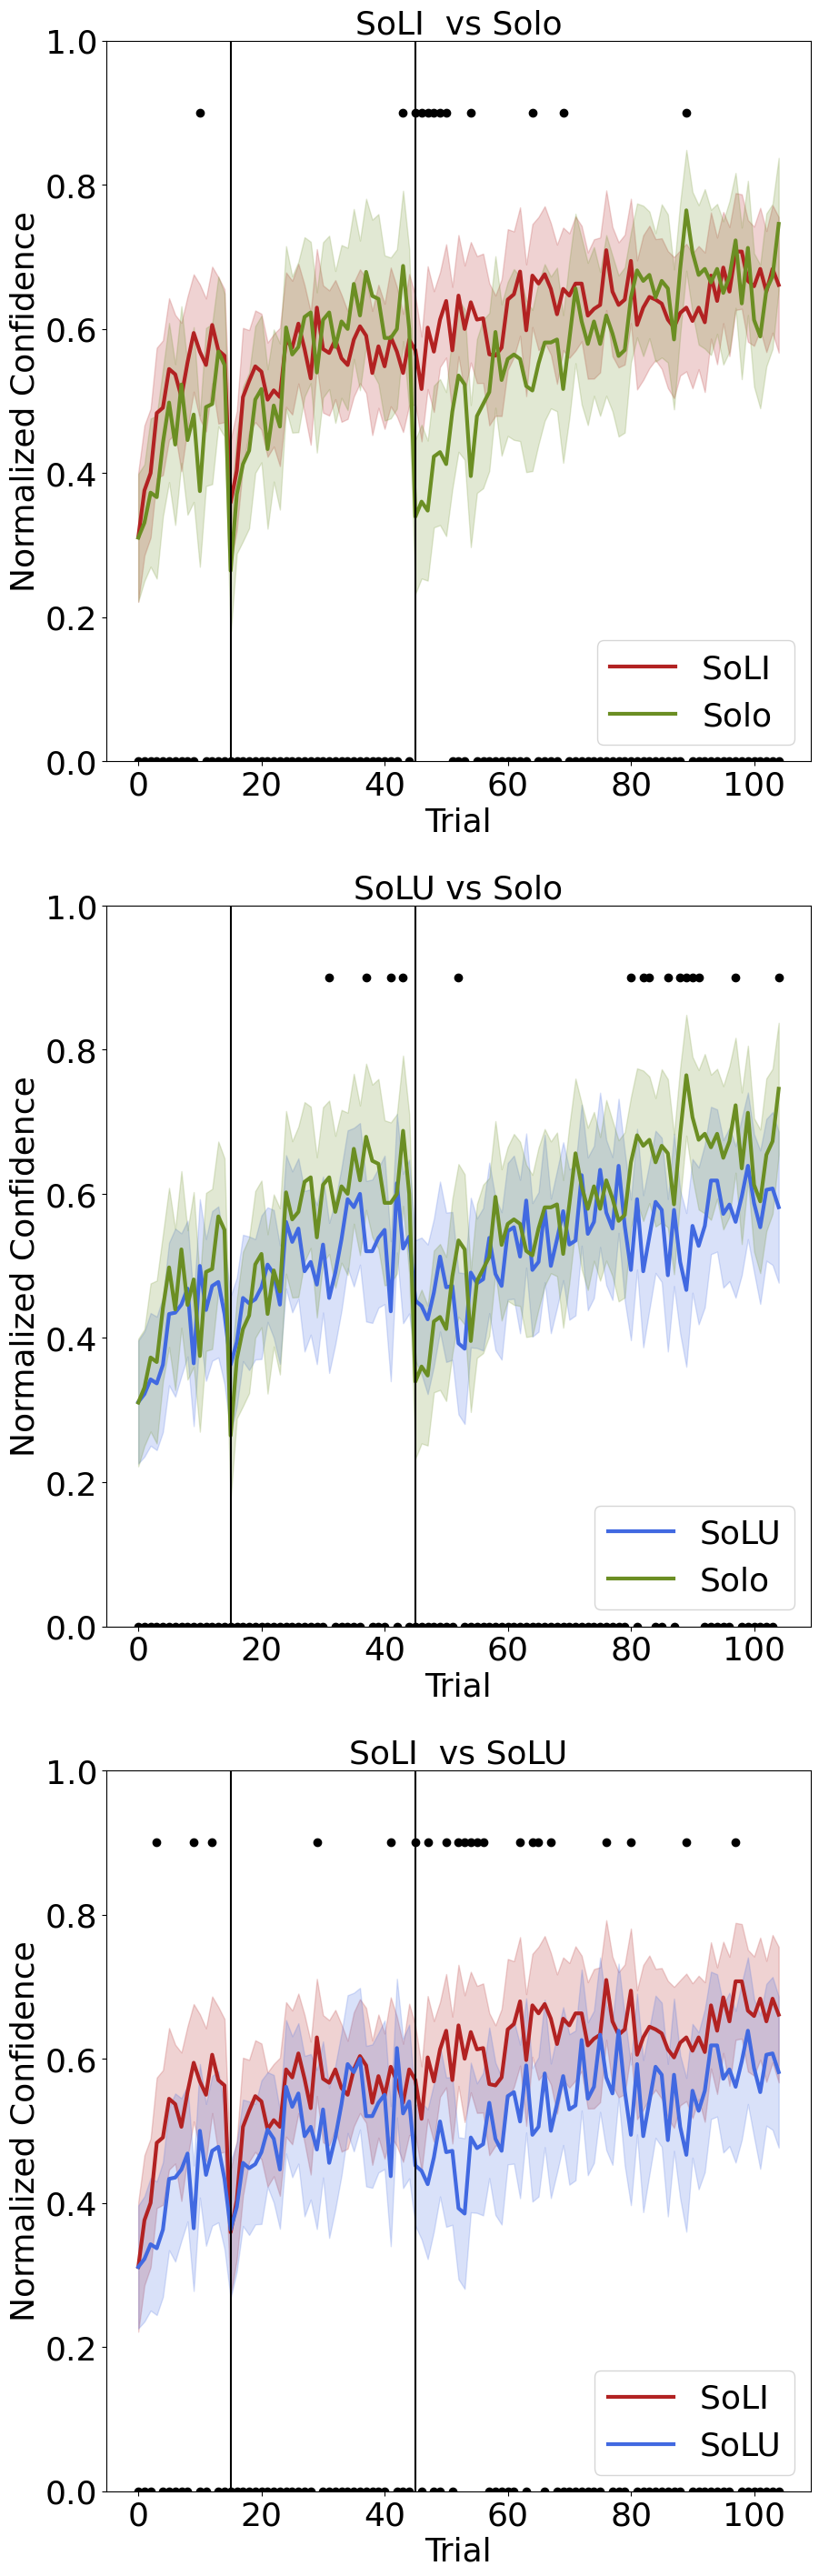

In [59]:
plot_conf(all_conf, g1_len, g2_len, [0, 1], 0.9, 0, 105)


In [63]:
all_rt = get_coloumn(all_sub_df, 'choice_rt', start=0, end=105, normalization=True)

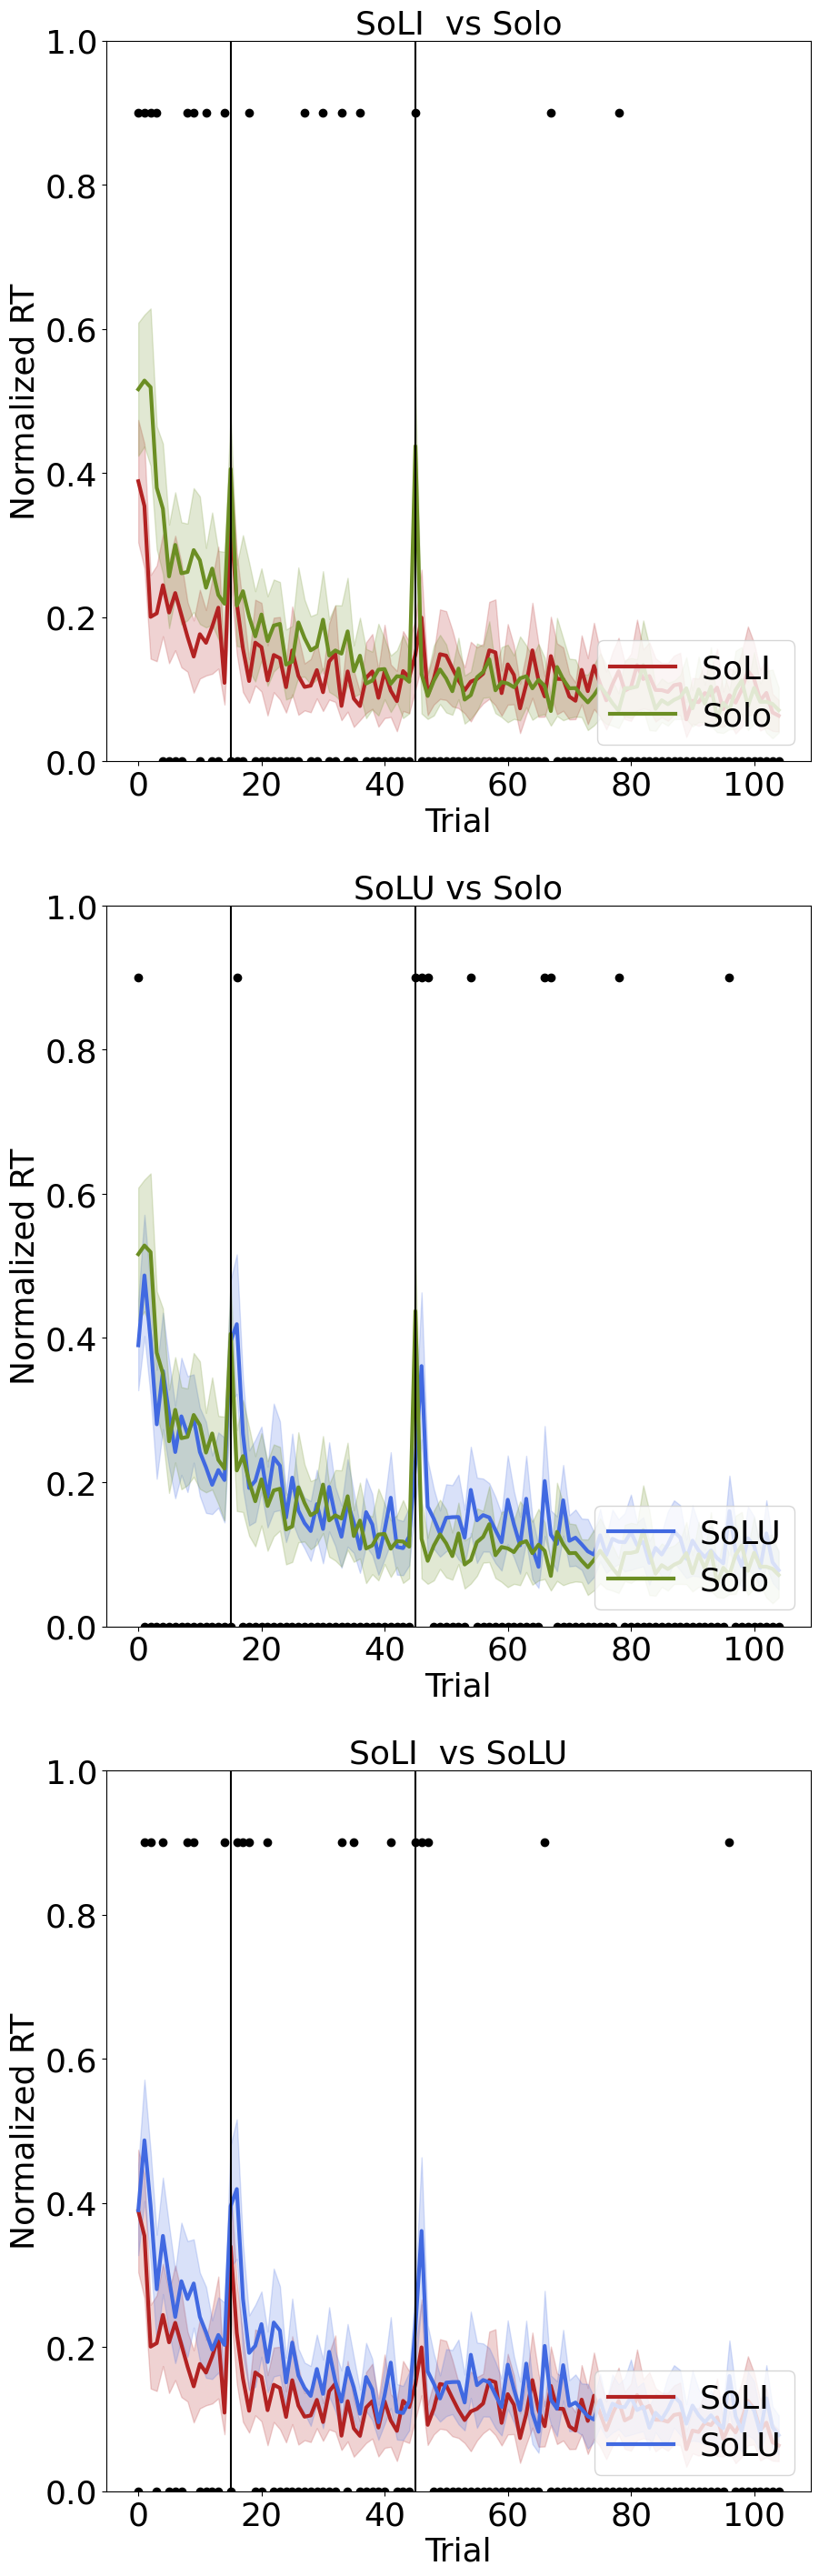

In [64]:
plot_conf(all_rt, g1_len, g2_len, [0, 1], 0.9, 0, 105)

In [38]:
IO_conf_pval, IO_conf_stat, IO_conf_sig = all_trials_ttest(all_conf, 0, g1_len, g1_len + g2_len, 130, 0, 105)
UO_conf_pval, UO_conf_stat, UO_conf_sig = all_trials_ttest(all_conf, g1_len, g1_len + g2_len, g1_len + g2_len, 130, 0, 105)
IU_conf_pval, IU_conf_stat, IU_conf_sig = all_trials_ttest(all_conf, 0, g1_len, g1_len, g1_len + g2_len, 0, 105)

Conf drop

In [39]:
soli_conf = all_conf[0:45]
solu_conf = all_conf[45:90]
solo_conf = all_conf[90:]

In [40]:
soli_conf[0].shape

(105,)

In [41]:
soli_b1_drop = []
soli_b2_drop = []
solu_b1_drop = []
solu_b2_drop = []
solo_b1_drop = []
solo_b2_drop = []
for idx in range(45):
    soli_b1_drop.append(soli_conf[idx][14] - soli_conf[idx][15])
    soli_b2_drop.append(soli_conf[idx][44] - soli_conf[idx][45])
    solu_b1_drop.append(solu_conf[idx][14] - solu_conf[idx][15])
    solu_b2_drop.append(solu_conf[idx][44] - solu_conf[idx][45])
soli_b1_drop = np.array(soli_b1_drop)
soli_b2_drop = np.array(soli_b2_drop)   
solu_b1_drop = np.array(solu_b1_drop)
solu_b2_drop = np.array(solu_b2_drop)

for idx in range(40):
    solo_b1_drop.append(solo_conf[idx][14] - solo_conf[idx][15])
    solo_b2_drop.append(solo_conf[idx][44] - solo_conf[idx][45])
solo_b1_drop = np.array(solo_b1_drop)
solo_b2_drop = np.array(solo_b2_drop) 

In [42]:
b1_IO_drop_t, b1_IO_drop_p = ttest_ind(soli_b1_drop, solo_b1_drop)
b2_IO_drop_t, b2_IO_drop_p = ttest_ind(soli_b2_drop, solo_b2_drop)

b1_UO_drop_t, b1_UO_drop_p = ttest_ind(solu_b1_drop, solo_b1_drop)
b2_UO_drop_t, b2_UO_drop_p = ttest_ind(solu_b2_drop, solo_b2_drop)

b1_IU_drop_t, b1_IU_drop_p = ttest_ind(soli_b1_drop, solu_b1_drop)
b2_IU_drop_t, b2_IU_drop_p = ttest_ind(soli_b2_drop, solu_b2_drop)


print('The P value for first block confidence drop between SoLI and Solo: ', b1_IO_drop_p)
print('The P value for second block confidence drop between SoLI and Solo: ', b2_IO_drop_p)
print('')
print('The P value for first block confidence drop between SoLU and Solo: ', b1_UO_drop_p)
print('The P value for second block confidence drop between SoLU and Solo: ', b2_UO_drop_p)
print('')
print('The P value for first block confidence drop between SoLI and SoLU: ', b1_IU_drop_p)
print('The P value for second block confidence drop between SoLI and SoLU: ', b2_IU_drop_p)

The P value for first block confidence drop between SoLI and Solo:  0.36312151592482267
The P value for second block confidence drop between SoLI and Solo:  0.0034036280731688765

The P value for first block confidence drop between SoLU and Solo:  0.024737432703058147
The P value for second block confidence drop between SoLU and Solo:  0.05351622802441223

The P value for first block confidence drop between SoLI and SoLU:  0.14726882602724697
The P value for second block confidence drop between SoLI and SoLU:  0.33881315274176227


# RL Model Fitting

In [59]:
all_sub_df = all_trained_4arm_df + all_not_trained_4arm_df
all_sub_2arm_df = all_trained_2arm_df + all_not_trained_2arm_df
g1_len = len(all_trained_4arm_df)
g2_len = len(all_not_trained_4arm_df)
# g3_len = len(all_bl_4arm_df)
g1 = 'SoLI '
g2 = 'SoLU'
# g3 = 'Solo'

## Value Based Models

$2arm$

In [60]:
def llik_td(x, *args):
    alpha, beta = x
    actions, rewards = args

    Q = np.zeros(2) * 0.5
    logp_actions = np.zeros(len(actions))

    for t, (a, r) in enumerate(zip(actions, rewards)):
        Q_ = Q * beta
        logp_action = Q_ - scipy.special.logsumexp(Q_)

        logp_actions[t] = logp_action[a]

        Q[a] = Q[a] + alpha * (r - Q[a])

    return -np.sum(logp_actions[1:])

$4 arm$

In [61]:
def Q_4arms(x, *args):
    alpha, beta = x
    actions, rewards = args

    Q = np.zeros(4) * 0.5
    logp_actions = np.zeros(len(actions))

    for t, (a, r) in enumerate(zip(actions, rewards)):
        Q_ = Q * beta
        logp_action = Q_ - scipy.special.logsumexp(Q_)

        logp_actions[t] = logp_action[a]

        Q[a] = Q[a] + alpha * (r - Q[a])

    return -np.sum(logp_actions[1:])

*Social Models*

In [62]:
def first_model_Qm(x, *args):
    alpha, beta, gm1, gm2, gm3 = x
    actions, rewards, ag_choices, chosen_ags = args
    
    Q = np.zeros(4)
    logp_actions = np.zeros(len(actions))
    for t, (a, r, ag_choice, chosen_ag) in enumerate(zip(actions, rewards, ag_choices, chosen_ags)):
        if t == 15 or t == 45:
            Q = np.ones(4) * np.mean(Q)
        if t > 14 and t < 45 and t % 3 == 0:
            obs_impact = np.zeros(4)
            try:
                ag_choice = eval(ag_choice)
            except:
                t = t
            obs_impact[ag_choice[0]] += gm1
            obs_impact[ag_choice[1]] += gm2
            obs_impact[ag_choice[2]] += gm3
            
            Q += obs_impact
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        elif t >= 45 and t % 3 == 0:
            gamma = 0
            try:
                ag_choice = eval(ag_choice)
            except:
                t = t
            obs_impact = np.zeros(4)
            if chosen_ag == 'A':
                gamma = gm1
            elif chosen_ag == 'B':
                gamma = gm2
            elif chosen_ag == 'C':
                gamma = gm3
            else:
                gamma = 0
            try:
                obs_impact[ag_choice] += gamma
            except:
                obs_impact = np.zeros(4)
            Q += obs_impact
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        else:
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
            
    return -np.sum(logp_actions[1:])
            

In [63]:
def first_model_Q0(x, *args):
    alpha, beta, gm1, gm2, gm3 = x
    actions, rewards, ag_choices, chosen_ags = args
    
    Q = np.zeros(4)
    logp_actions = np.zeros(len(actions))
    for t, (a, r, ag_choice, chosen_ag) in enumerate(zip(actions, rewards, ag_choices, chosen_ags)):
        if t == 15 or t == 45:
            Q = np.zeros(4)
        if t > 14 and t < 45 and t % 3 == 0:
            obs_impact = np.zeros(4)
            try:
                ag_choice = eval(ag_choice)
            except:
                t = t
            obs_impact[ag_choice[0]] += gm1
            obs_impact[ag_choice[1]] += gm2
            obs_impact[ag_choice[2]] += gm3
            
            Q += obs_impact
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        elif t >= 45 and t % 3 == 0:
            gamma = 0
            try:
                ag_choice = eval(ag_choice)
            except:
                t = t
            obs_impact = np.zeros(4)
            if chosen_ag == 'A':
                gamma = gm1
            elif chosen_ag == 'B':
                gamma = gm2
            elif chosen_ag == 'C':
                gamma = gm3
            else:
                gamma = 0
            try:
                obs_impact[ag_choice] += gamma
            except:
                obs_impact = np.zeros(4)
            Q += obs_impact
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        else:
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
            
    return -np.sum(logp_actions[1:])
            

2 arm fitting

In [64]:
import os
import scipy
all_2arm_alpha = []
all_2arm_epsilon = []
for sub in all_sub_2arm_df:
  frame = sub
  actions = frame['choice'][:105]
  rewards = (frame['outcome'][:105] == 'win') * 1
  true_alpha = 0.1
  true_beta = 0.5
  x0 = [true_alpha, true_beta]
  result = scipy.optimize.minimize(llik_td, x0, args=(actions, rewards), method="L-BFGS-B" ,bounds=((0.01, 1), (0.01, 100)))
  print(result)
  print("")
  print(f"MLE: alpha = {result.x[0]:.2f}")
  print(f"MLE: epsilon = {result.x[1]:.2f}")
  all_2arm_alpha.append(result.x[0])
  all_2arm_epsilon.append(result.x[1])
  

  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 8.067594936864998
        x: [ 3.787e-01  4.506e+00]
      nit: 13
      jac: [ 1.137e-05  1.954e-06]
     nfev: 51
     njev: 17
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.38
MLE: epsilon = 4.51
  message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 3.298200785321147
        x: [ 9.931e-01  1.000e+02]
      nit: 31
      jac: [ 8.882e-08 -2.327e-05]
     nfev: 117
     njev: 39
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.99
MLE: epsilon = 100.00
  message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 20.10158995025867
        x: [ 1.000e-02  1.000e-02]
      nit: 2
      jac: [ 2.948e-02  3.220e-02]
     nfev: 15
     njev: 5
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.01
MLE: epsilon = 0.01
  message: CONVERGENCE: N

Base Line Model Fitting

In [65]:
import os
import scipy
all_bl_alpha = []
all_bl_epsilon = []
all_bl_neg_ll = []
for sub in all_bl_4arm_df:
  frame = sub
  actions = frame['choice'][:105]
  rewards = (frame['outcome'][:105] == 'win') * 1
  true_alpha = 0.1
  true_beta = 0.5
  x0 = [true_alpha, true_beta]
  result = scipy.optimize.minimize(Q_4arms, x0, args=(actions, rewards), method="L-BFGS-B" ,bounds=((0.01, 1), (0.01, 100)))
  print(result)
  print("")
  print(f"MLE: alpha = {result.x[0]:.2f}")
  print(f"MLE: epsilon = {result.x[1]:.2f}")
  all_bl_alpha.append(result.x[0])
  all_bl_epsilon.append(result.x[1])
  all_bl_neg_ll.append(result.fun)

  message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 73.76548614448213
        x: [ 3.864e-01  5.882e+00]
      nit: 8
      jac: [ 1.421e-06 -1.421e-06]
     nfev: 33
     njev: 11
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.39
MLE: epsilon = 5.88
  message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 126.07571439207986
        x: [ 1.000e+00  1.438e+00]
      nit: 7
      jac: [-3.085e-01 -1.421e-06]
     nfev: 30
     njev: 10
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 1.00
MLE: epsilon = 1.44
  message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 144.17681179004938
        x: [ 1.000e-02  1.000e-02]
      nit: 1
      jac: [ 1.966e-01  2.199e-01]
     nfev: 6
     njev: 2
 hess_inv: <2x2 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.01
MLE: epsilon = 0.01
  message: CONVERGENCE: NORM

Value Based model with Q mean

In [66]:
import os
import scipy
all_alpha_Qmean = []
all_gamma_Qmean = []
all_epsilon_Qmean = []
all_neg_ll_Qmean = []



for sub in all_sub_df:

  frame = sub  
  actions = frame['choice'][:105]
  rewards = (frame['outcome'][:105] == 'win') * 1
  ag_choices = frame['agent_choices'][:105]
  chosen_ags = frame['chosen_agent'][:105]
  true_alpha = 0.1
  true_beta = 0.5
  x0 = [true_alpha, true_beta, 0.2, 0.2, 0.2]
  result = scipy.optimize.minimize(first_model_Qm, x0, args=(actions, rewards, ag_choices, chosen_ags), method="L-BFGS-B" ,bounds=((0.01, 1), (0.01, 100), (-1, 1), (-1, 1), (-1, 1)))
  print(result)
  print("")
  print(f"MLE: alpha = {result.x[0]:.2f}")
  print(f"MLE: epsilon = {result.x[1]:.2f}")
  print(f"MLE: gamma1 = {result.x[2]:.2f}")
  print(f"MLE: gamma2 = {result.x[3]:.2f}")
  print(f"MLE: gamma3 = {result.x[4]:.2f}")
  all_alpha_Qmean.append(result.x[0])
  all_gamma_Qmean.append([result.x[2], result.x[3], result.x[4]])
  all_epsilon_Qmean.append(result.x[1])
  all_neg_ll_Qmean.append(result.fun)

  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 107.90235780371572
        x: [ 8.245e-01  2.284e+00  1.000e+00  3.070e-01  3.904e-01]
      nit: 15
      jac: [-3.212e-04  4.832e-05 -1.977e+01  3.411e-05  4.974e-05]
     nfev: 108
     njev: 18
 hess_inv: <5x5 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.82
MLE: epsilon = 2.28
MLE: gamma1 = 1.00
MLE: gamma2 = 0.31
MLE: gamma3 = 0.39
  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 54.25903096353359
        x: [ 4.447e-01  4.997e+00  1.541e-01 -2.947e-01  8.659e-02]
      nit: 25
      jac: [-1.802e-03  2.082e-04  2.476e-03 -2.156e-03 -3.919e-03]
     nfev: 174
     njev: 29
 hess_inv: <5x5 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.44
MLE: epsilon = 5.00
MLE: gamma1 = 0.15
MLE: gamma2 = -0.29
MLE: gamma3 = 0.09
  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 79.

Value Based Model with Q 0

In [67]:
all_alpha_Q0 = []
all_gamma_Q0 = []
all_epsilon_Q0 = []
all_neg_ll_Q0 = []
all_Q0 = []
for sub in all_sub_df:
  frame = sub  
  actions = frame['choice'][:105]
  rewards = (frame['outcome'][:105] == 'win') * 1
  ag_choices = frame['agent_choices'][:105]
  chosen_ags = frame['chosen_agent'][:105]
  true_alpha = 0.1
  true_beta = 0.5
  x0 = [true_alpha, true_beta, 0.2, 0.2, 0.2]
  result = scipy.optimize.minimize(first_model_Q0, x0, args=(actions, rewards, ag_choices, chosen_ags), method="L-BFGS-B" ,bounds=((0.01, 1), (0.01, 100), (-1, 1), (-1, 1), (-1, 1)))
  
  print("")
  print(f"MLE: alpha = {result.x[0]:.2f}")
  print(f"MLE: epsilon = {result.x[1]:.2f}")
  print(f"MLE: gamma1 = {result.x[2]:.2f}")
  print(f"MLE: gamma2 = {result.x[3]:.2f}")
  print(f"MLE: gamma3 = {result.x[4]:.2f}")
  all_alpha_Q0.append(result.x[0])
  all_gamma_Q0.append([result.x[2], result.x[3], result.x[4]])
  all_epsilon_Q0.append(result.x[1])
  all_neg_ll_Q0.append(result.fun)
print(result)


MLE: alpha = 0.80
MLE: epsilon = 2.26
MLE: gamma1 = 1.00
MLE: gamma2 = 0.30
MLE: gamma3 = 0.39

MLE: alpha = 0.38
MLE: epsilon = 5.59
MLE: gamma1 = 0.12
MLE: gamma2 = -0.16
MLE: gamma3 = 0.16

MLE: alpha = 0.11
MLE: epsilon = 2.54
MLE: gamma1 = 0.52
MLE: gamma2 = 0.16
MLE: gamma3 = 0.28

MLE: alpha = 0.42
MLE: epsilon = 5.10
MLE: gamma1 = 0.22
MLE: gamma2 = 0.07
MLE: gamma3 = 0.05

MLE: alpha = 0.14
MLE: epsilon = 2.66
MLE: gamma1 = 0.39
MLE: gamma2 = 0.32
MLE: gamma3 = 0.19

MLE: alpha = 0.53
MLE: epsilon = 5.82
MLE: gamma1 = 0.01
MLE: gamma2 = -0.06
MLE: gamma3 = 0.42

MLE: alpha = 0.18
MLE: epsilon = 5.02
MLE: gamma1 = 0.04
MLE: gamma2 = 0.04
MLE: gamma3 = -0.05

MLE: alpha = 0.70
MLE: epsilon = 4.72
MLE: gamma1 = 0.17
MLE: gamma2 = 0.33
MLE: gamma3 = 0.02

MLE: alpha = 0.33
MLE: epsilon = 3.18
MLE: gamma1 = 1.00
MLE: gamma2 = 0.13
MLE: gamma3 = 0.69

MLE: alpha = 0.50
MLE: epsilon = 1.58
MLE: gamma1 = -0.22
MLE: gamma2 = 1.00
MLE: gamma3 = -0.03

MLE: alpha = 0.22
MLE: epsilon = 5

Sorting Gammas

In [68]:
all_sub_ag_type = []
for idx, sub in enumerate(all_sub_df):
    all_sub_ag_type.append(list(sub['agent types'])[-1])

In [69]:
sorted_g_0 = []
sorted_g_m = []
for idx, sub in enumerate(all_sub_ag_type):
    gamma_Q0 = [0, 0, 0]
    gamma_Qm = [0, 0, 0]
    ag_type = eval(sub)
    gamma_Q0[0] = all_gamma_Q0[idx][ag_type.index(0)]
    gamma_Q0[1] = all_gamma_Q0[idx][ag_type.index(1)]
    gamma_Q0[2] = all_gamma_Q0[idx][ag_type.index(2)]
    
    gamma_Qm[0] = all_gamma_Qmean[idx][ag_type.index(0)]
    gamma_Qm[1] = all_gamma_Qmean[idx][ag_type.index(1)]
    gamma_Qm[2] = all_gamma_Qmean[idx][ag_type.index(2)]
    sorted_g_0.append(gamma_Q0.copy())
    sorted_g_m.append(gamma_Qm.copy())
sorted_g_0 = np.array(sorted_g_0)
sorted_g_m = np.array(sorted_g_m)

## Policy Based Models

In [70]:
def first_policy_based_model_Qmean(x, *args):
    alpha, beta, gm1, gm2, gm3 = x
    actions, rewards, ag_choices, chosen_ags = args
    
    Q = np.zeros(4)
    logp_actions = np.zeros(len(actions))
    for t, (a, r, ag_choice, chosen_ag) in enumerate(zip(actions, rewards, ag_choices, chosen_ags)):
        if t == 15 or t == 45:
            Q = np.ones(4) * np.mean(Q)
            
        if t > 14 and t < 45:
            if t % 3 == 0:
                obs_impact = np.zeros(4)
                try:
                    ag_choice = eval(ag_choice)
                except:
                    t = t
                obs_impact[ag_choice[0]] += gm1
                obs_impact[ag_choice[1]] += gm2
                obs_impact[ag_choice[2]] += gm3
                   
            Q_ = (Q + obs_impact) * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        elif t >= 45:
            if t % 3 == 0:
                gamma = 0
                try:
                    ag_choice = eval(ag_choice)
                except:
                    t = t
                obs_impact = np.zeros(4)
                if chosen_ag == 'A':
                    gamma = gm1
                elif chosen_ag == 'B':
                    gamma = gm2
                elif chosen_ag == 'C':
                    gamma = gm3
                else:
                    gamma = 0
                try:
                    obs_impact[ag_choice] += gamma
                except:
                    obs_impact = np.zeros(4)

            Q_ = (Q + obs_impact) * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
            
        else: 
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        
        
    return -np.sum(logp_actions[1:])

In [71]:
def first_policy_based_model_Q0(x, *args):
    alpha, beta, gm1, gm2, gm3 = x
    actions, rewards, ag_choices, chosen_ags = args
    
    Q = np.zeros(4)
    logp_actions = np.zeros(len(actions))
    for t, (a, r, ag_choice, chosen_ag) in enumerate(zip(actions, rewards, ag_choices, chosen_ags)):
        if t == 15 or t == 45:
            Q = np.zeros(4)
            
        if t > 14 and t < 45:
            if t % 3 == 0:
                obs_impact = np.zeros(4)
                try:
                    ag_choice = eval(ag_choice)
                except:
                    t = t
                obs_impact[ag_choice[0]] += gm1
                obs_impact[ag_choice[1]] += gm2
                obs_impact[ag_choice[2]] += gm3
                   
            Q_ = (Q + obs_impact) * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        elif t >= 45:
            if t % 3 == 0:
                gamma = 0
                try:
                    ag_choice = eval(ag_choice)
                except:
                    t = t
                obs_impact = np.zeros(4)
                if chosen_ag == 'A':
                    gamma = gm1
                elif chosen_ag == 'B':
                    gamma = gm2
                elif chosen_ag == 'C':
                    gamma = gm3
                else:
                    gamma = 0
                try:
                    obs_impact[ag_choice] += gamma
                except:
                    obs_impact = np.zeros(4)

            Q_ = (Q + obs_impact) * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
            
        else: 
            Q_ = Q * beta
            logp_action = Q_ - scipy.special.logsumexp(Q_)
            logp_actions[t] = logp_action[a]
            Q[a] = Q[a] + alpha * (r - Q[a])
        
        
    return -np.sum(logp_actions[1:])

In [72]:
import os
import scipy
all_alpha_pQmean = []
all_gamma_pQmean = []
all_beta_pQmean = []
all_neg_ll_pQmean = []

for sub in all_sub_df:

  frame = sub  
  actions = frame['choice'][:105]
  rewards = (frame['outcome'][:105] == 'win') * 1
  ag_choices = frame['agent_choices'][:105]
  chosen_ags = frame['chosen_agent'][:105]
  true_alpha = 0.1
  true_beta = 0.5
  x0 = [true_alpha, true_beta, 0.2, 0.2, 0.2]
  result = scipy.optimize.minimize(first_policy_based_model_Qmean, x0, args=(actions, rewards, ag_choices, chosen_ags), method="L-BFGS-B" ,bounds=((0.01, 1), (0.01, 100), (-1, 1), (-1, 1), (-1, 1)))
  print(result)
  print("")
  print(f"MLE: alpha = {result.x[0]:.2f}")
  print(f"MLE: epsilon = {result.x[1]:.2f}")
  print(f"MLE: gamma1 = {result.x[2]:.2f}")
  print(f"MLE: gamma2 = {result.x[3]:.2f}")
  print(f"MLE: gamma3 = {result.x[4]:.2f}")
  all_alpha_pQmean.append(result.x[0])
  all_gamma_pQmean.append([result.x[2], result.x[3], result.x[4]])
  all_beta_pQmean.append(result.x[1])
  all_neg_ll_pQmean.append(result.fun)

  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 113.9676909957781
        x: [ 1.206e-01  4.265e+00  2.714e-01  1.712e-01  1.750e-02]
      nit: 15
      jac: [ 4.604e-04  2.558e-05 -4.178e-04  1.791e-04  5.784e-04]
     nfev: 108
     njev: 18
 hess_inv: <5x5 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.12
MLE: epsilon = 4.26
MLE: gamma1 = 0.27
MLE: gamma2 = 0.17
MLE: gamma3 = 0.02
  message: CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL
  success: True
   status: 0
      fun: 49.96479762852634
        x: [ 2.382e-01  9.144e+00  1.569e-01 -9.683e-04  2.657e-01]
      nit: 14
      jac: [ 0.000e+00  0.000e+00  1.421e-06 -4.263e-06 -4.974e-06]
     nfev: 108
     njev: 18
 hess_inv: <5x5 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.24
MLE: epsilon = 9.14
MLE: gamma1 = 0.16
MLE: gamma2 = -0.00
MLE: gamma3 = 0.27
  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 51.

In [73]:
import os
import scipy
all_alpha_pQ0 = []
all_gamma_pQ0 = []
all_beta_pQ0 = []
all_neg_ll_pQ0 = []

for sub in all_sub_df:

  frame = sub  
  actions = frame['choice'][:105]
  rewards = (frame['outcome'][:105] == 'win') * 1
  ag_choices = frame['agent_choices'][:105]
  chosen_ags = frame['chosen_agent'][:105]
  true_alpha = 0.1
  true_beta = 0.5
  x0 = [true_alpha, true_beta, 0.2, 0.2, 0.2]
  result = scipy.optimize.minimize(first_policy_based_model_Q0, x0, args=(actions, rewards, ag_choices, chosen_ags), method="L-BFGS-B" ,bounds=((0.01, 1), (0.01, 100), (-1, 1), (-1, 1), (-1, 1)))
  print(result)
  print("")
  print(f"MLE: alpha = {result.x[0]:.2f}")
  print(f"MLE: epsilon = {result.x[1]:.2f}")
  print(f"MLE: gamma1 = {result.x[2]:.2f}")
  print(f"MLE: gamma2 = {result.x[3]:.2f}")
  print(f"MLE: gamma3 = {result.x[4]:.2f}")
  all_alpha_pQ0.append(result.x[0])
  all_gamma_pQ0.append([result.x[2], result.x[3], result.x[4]])
  all_beta_pQ0.append(result.x[1])
  all_neg_ll_pQ0.append(result.fun)


  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 114.04012013155847
        x: [ 1.683e-01  3.312e+00  3.559e-01  2.015e-01  4.927e-02]
      nit: 12
      jac: [-1.009e-04  0.000e+00  5.826e-05 -5.116e-05 -1.421e-06]
     nfev: 90
     njev: 15
 hess_inv: <5x5 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.17
MLE: epsilon = 3.31
MLE: gamma1 = 0.36
MLE: gamma2 = 0.20
MLE: gamma3 = 0.05
  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 48.551102439063484
        x: [ 3.295e-01  6.337e+00  1.771e-01 -4.579e-02  3.574e-01]
      nit: 15
      jac: [-1.492e-05 -5.684e-06 -1.137e-05  4.974e-06  2.274e-05]
     nfev: 114
     njev: 19
 hess_inv: <5x5 LbfgsInvHessProduct with dtype=float64>

MLE: alpha = 0.33
MLE: epsilon = 6.34
MLE: gamma1 = 0.18
MLE: gamma2 = -0.05
MLE: gamma3 = 0.36
  message: CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH
  success: True
   status: 0
      fun: 51.

Sorting Gammas

In [74]:
all_sub_ag_type = []
for idx, sub in enumerate(all_sub_df):
    all_sub_ag_type.append(list(sub['agent types'])[-1])

In [75]:
sorted_pg_m = []
sorted_pg_0 = []
for idx, sub in enumerate(all_sub_ag_type):
    gamma_pQm = [0, 0, 0]
    gamma_pQ0 = [0, 0, 0]
    ag_type = eval(sub)
    gamma_pQm[0] = all_gamma_pQmean[idx][ag_type.index(0)]
    gamma_pQm[1] = all_gamma_pQmean[idx][ag_type.index(1)]
    gamma_pQm[2] = all_gamma_pQmean[idx][ag_type.index(2)]
    
    gamma_pQ0[0] = all_gamma_pQ0[idx][ag_type.index(0)]
    gamma_pQ0[1] = all_gamma_pQ0[idx][ag_type.index(1)]
    gamma_pQ0[2] = all_gamma_pQ0[idx][ag_type.index(2)]
    
    

    sorted_pg_m.append(gamma_pQm.copy())
    sorted_pg_0.append(gamma_pQ0.copy())

sorted_pg_m = np.array(sorted_pg_m)
sorted_pg_0 = np.array(sorted_pg_0)

## Comparing Value Based and Policy Based Models

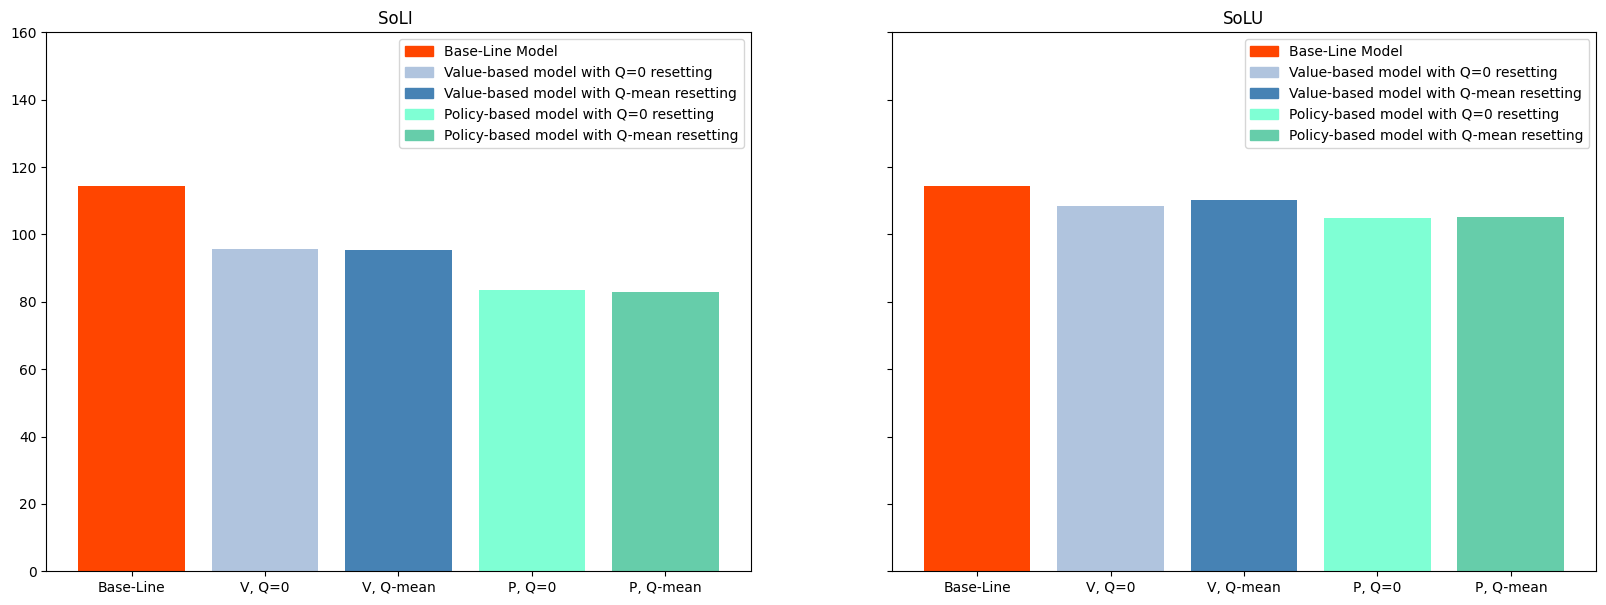

In [76]:
x = ['Base-Line', 'V, Q=0', 'V, Q-mean', 'P, Q=0', 'P, Q-mean']
trained_mean_nll = [np.mean(all_bl_neg_ll), np.mean(all_neg_ll_Q0[:g1_len]), np.mean(all_neg_ll_Qmean[:g1_len]), np.mean(all_neg_ll_pQ0[:g1_len]), np.mean(all_neg_ll_pQmean[:g1_len])]
not_trained_mean_nll = [np.mean(all_bl_neg_ll), np.mean(all_neg_ll_Q0[g1_len:]), np.mean(all_neg_ll_Qmean[g1_len:]), np.mean(all_neg_ll_pQ0[g1_len:]), np.mean(all_neg_ll_pQmean[g1_len:])]
clr = ['orangered', 'lightsteelblue', 'steelblue', 'aquamarine', 'mediumaquamarine']
labels = ['Base-Line Model', 'Value-based model with Q=0 resetting', 'Value-based model with Q-mean resetting', 'Policy-based model with Q=0 resetting', 'Policy-based model with Q-mean resetting']
fig, axs = plt.subplots(1, 2, sharey='all', figsize=(20, 7))
# fig.suptitle('Bar plot of mean NLL of all models for each group')

axs[0].set_ylim([0, 160])
axs[0].bar(x, trained_mean_nll, color=clr)
axs[0].set_title(g1)

axs[1].bar(x, not_trained_mean_nll, color=clr)
axs[1].set_title(g2)

from matplotlib.patches import Patch
handles = [Patch(color=clr[i], label=labels[i]) for i in range(len(clr))]
axs[0].legend(handles=handles, loc='best')
axs[1].legend(handles=handles, loc='best')

plt.show()
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/RL-both-NLL.svg')

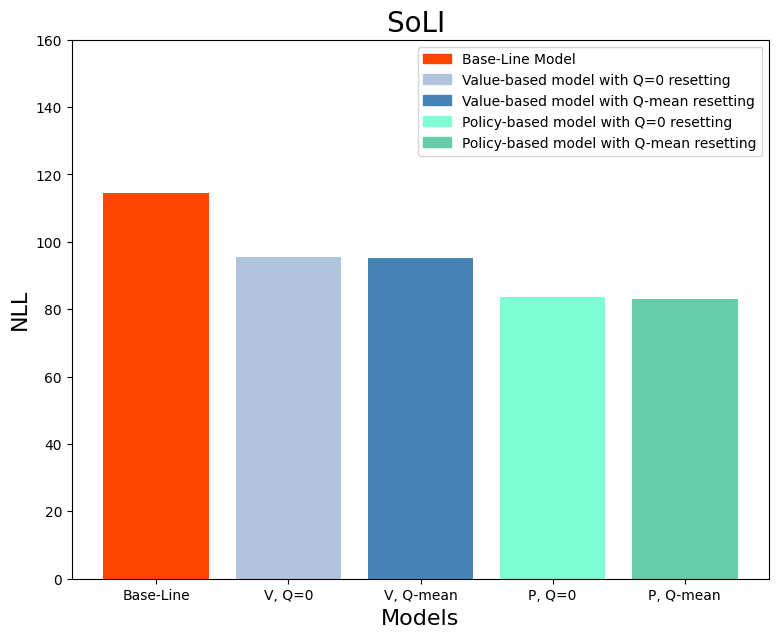

In [77]:
x = ['Base-Line', 'V, Q=0', 'V, Q-mean', 'P, Q=0', 'P, Q-mean']
trained_mean_nll = [np.mean(all_bl_neg_ll), np.mean(all_neg_ll_Q0[:g1_len]), np.mean(all_neg_ll_Qmean[:g1_len]), np.mean(all_neg_ll_pQ0[:g1_len]), np.mean(all_neg_ll_pQmean[:g1_len])]
clr = ['orangered', 'lightsteelblue', 'steelblue', 'aquamarine', 'mediumaquamarine']
labels = ['Base-Line Model', 'Value-based model with Q=0 resetting', 'Value-based model with Q-mean resetting', 'Policy-based model with Q=0 resetting', 'Policy-based model with Q-mean resetting']
fig, axs = plt.subplots(1, 1, sharey='all', figsize=(9, 7))
# fig.suptitle('Bar plot of mean NLL of all models for each group')

axs.set_ylim([0, 160])
axs.bar(x, trained_mean_nll, color=clr)
axs.set_title(g1, fontsize=20)
axs.set_xlabel('Models', fontsize=16)
axs.set_ylabel('NLL', fontsize=16)



from matplotlib.patches import Patch
handles = [Patch(color=clr[i], label=labels[i]) for i in range(len(clr))]
axs.legend(handles=handles, loc='best')

plt.show()
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/RL-NLL.svg')


In [78]:
from scipy.stats import ttest_ind

t_stat, pval = ttest_ind(all_neg_ll_Qmean[:g1_len], all_neg_ll_pQmean[:g1_len])
print('The result of t-test between V-based with Q-mean resetting and P-based with Q-mean resetting in train group:')
print('t-stat:', t_stat, ' P-value:', pval)

The result of t-test between V-based with Q-mean resetting and P-based with Q-mean resetting in train group:
t-stat: 1.962364895883123  P-value: 0.052879537113143846


In [79]:
from scipy.stats import mannwhitneyu

u_stat, pval = mannwhitneyu(all_neg_ll_Qmean[:g1_len], all_neg_ll_pQmean[:g1_len])
print('The result of Mann-Whitney test between V-based with Q-mean resetting and P-based with Q-mean resetting in train group:')
print('u-stat:', u_stat, ' P-value:', pval)

The result of Mann-Whitney test between V-based with Q-mean resetting and P-based with Q-mean resetting in train group:
u-stat: 1264.0  P-value: 0.04281658092357167


In [80]:
from scipy.stats import mannwhitneyu

u_stat, pval = mannwhitneyu(all_bl_neg_ll, all_neg_ll_pQmean[:g1_len])
print('The result of Mann-Whitney test between V-based with Q-mean resetting and P-based with Q-mean resetting in train group:')
print('u-stat:', u_stat, ' P-value:', pval)

The result of Mann-Whitney test between V-based with Q-mean resetting and P-based with Q-mean resetting in train group:
u-stat: 1389.0  P-value: 1.700270056375422e-05


In [81]:
from scipy.stats import mannwhitneyu

u_stat, pval = mannwhitneyu(all_neg_ll_Qmean[:g1_len], all_neg_ll_pQmean[:g1_len])
print('The result of Mann-Whitney test between V-based with Q-mean resetting and P-based with Q-mean resetting in train group:')
print('u-stat:', u_stat, ' P-value:', pval)

The result of Mann-Whitney test between V-based with Q-mean resetting and P-based with Q-mean resetting in train group:
u-stat: 1264.0  P-value: 0.04281658092357167


## Distributions

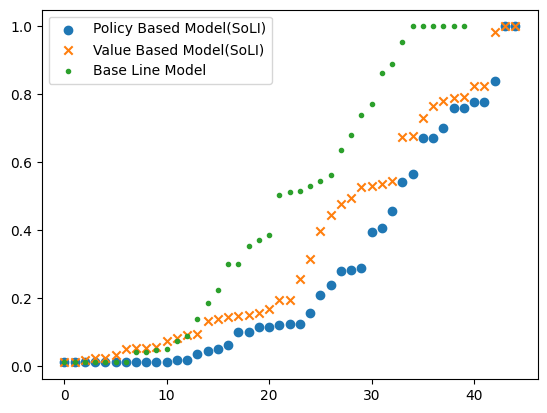

In [82]:
x = [i for i in range(g1_len)]
x2 = [i for i in range(40)]
plt.scatter(x, np.sort(np.array(all_alpha_pQmean[:g1_len])), marker='o', label='Policy Based Model(SoLI)')
plt.scatter(x, np.sort(np.array(all_alpha_Qmean[:g1_len])), marker='x', label='Value Based Model(SoLI)')
plt.scatter(x2, np.sort(np.array(all_bl_alpha)), marker='.', label='Base Line Model')
plt.legend()


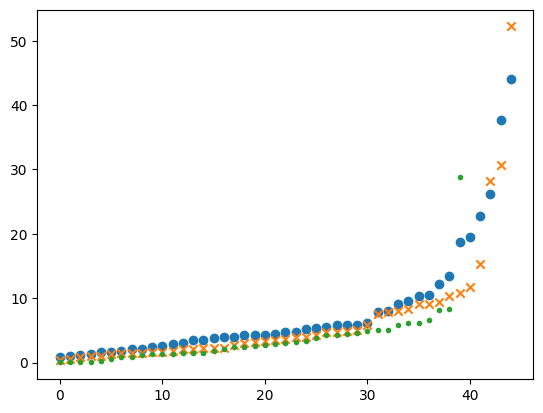

In [83]:
plt.scatter(x, np.sort(np.array(all_beta_pQmean[:g1_len])), marker='o', label='Policy Based Model(SoLI)')
plt.scatter(x, np.sort(np.array(all_epsilon_Qmean[:g1_len])), marker='x', label='Value Based Model(SoLI)')
plt.scatter(x2, np.sort(np.array(all_bl_epsilon)), marker='.', label='Base Line Model')


Gammas

best

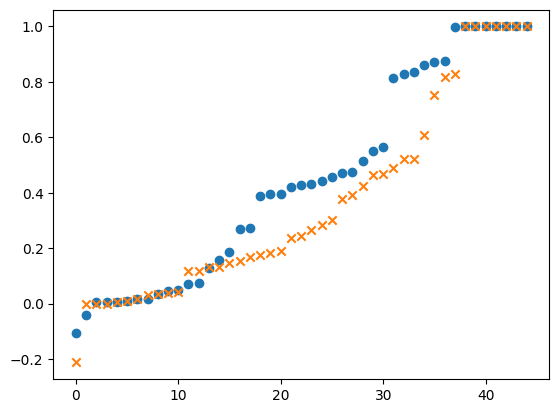

In [84]:
plt.scatter(x, np.sort(sorted_pg_m[:g1_len, 0]), marker='o')
plt.scatter(x, np.sort(sorted_g_m[:g1_len, 0]), marker = 'x')

Second

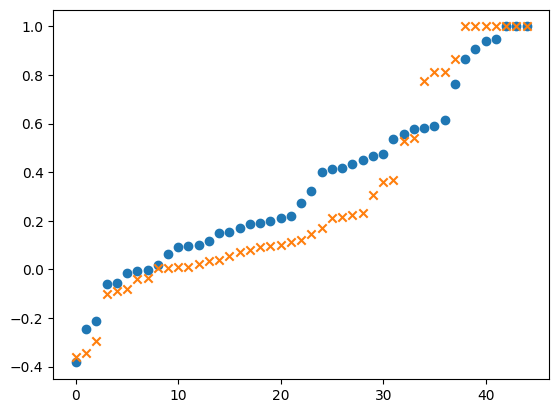

In [85]:
plt.scatter(x, np.sort(sorted_pg_m[:g1_len, 1]), marker='o')
plt.scatter(x, np.sort(sorted_g_m[:g1_len, 1]), marker = 'x')

worst

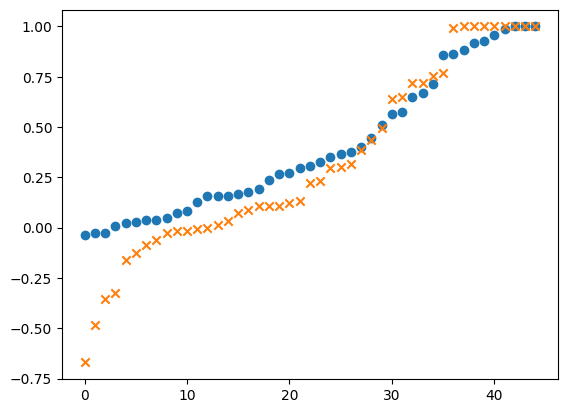

In [86]:
plt.scatter(x, np.sort(sorted_pg_m[:g1_len, 2]), marker='o')
plt.scatter(x, np.sort(sorted_g_m[:g1_len, 2]), marker = 'x')

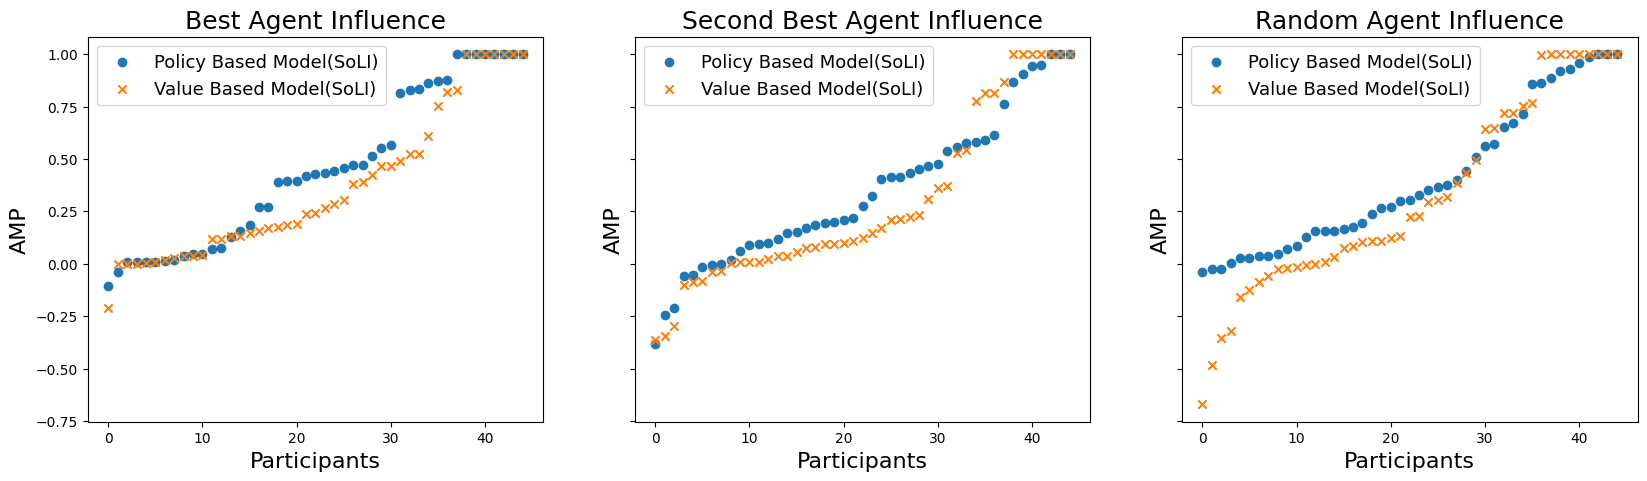

In [87]:
fig, axs = plt.subplots(1, 3, sharey='all', figsize=(20, 5))
x1 = [i for i in range(45)]
axs[0].scatter(x1, np.sort(sorted_pg_m[:g1_len, 0]), marker='o', label='Policy Based Model(SoLI)')
axs[0].scatter(x1, np.sort(sorted_g_m[:g1_len, 0]), marker = 'x', label='Value Based Model(SoLI)')
axs[0].set_title('Best Agent Influence', fontsize=18)
axs[0].set_xlabel('Participants', fontsize=16)
axs[0].set_ylabel('AMP', fontsize=16)
axs[0].legend(loc=2, prop={'size': 13})

axs[1].scatter(x1, np.sort(sorted_pg_m[:g1_len, 1]), marker='o', label='Policy Based Model(SoLI)')
axs[1].scatter(x1, np.sort(sorted_g_m[:g1_len, 1]), marker = 'x', label='Value Based Model(SoLI)')
axs[1].set_title('Second Best Agent Influence', fontsize=18)
axs[1].set_xlabel('Participants', fontsize=16)
axs[1].set_ylabel('AMP', fontsize=16)
axs[1].legend(loc=2, prop={'size': 13})

axs[2].scatter(x1, np.sort(sorted_pg_m[:g1_len, 2]), marker='o', label='Policy Based Model(SoLI)')
axs[2].scatter(x1, np.sort(sorted_g_m[:g1_len, 2]), marker = 'x', label='Value Based Model(SoLI)')
axs[2].set_title('Random Agent Influence', fontsize=18)
axs[2].set_xlabel('Participants', fontsize=16)
axs[2].set_ylabel('AMP', fontsize=16)
axs[2].legend(loc=2, prop={'size': 13});
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/Gammas-Dist.svg')


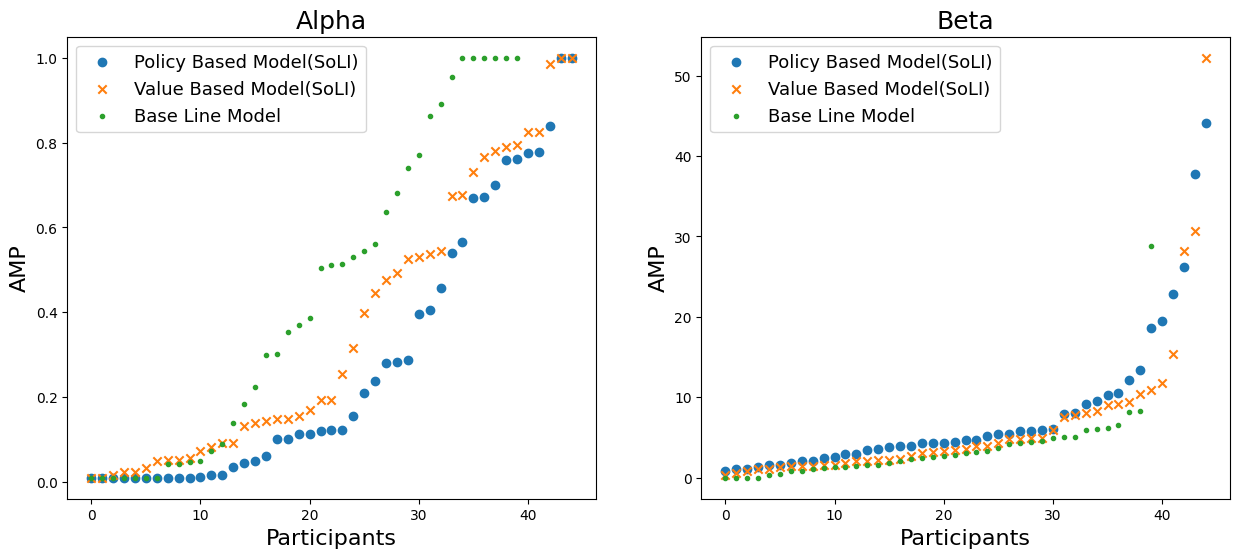

In [88]:
fig, axs = plt.subplots(1, 2, sharex='all', figsize=(15, 6))
x1 = [i for i in range(45)]
x2 = [i for i in range(40)]
axs[0].scatter(x1, np.sort(np.array(all_alpha_pQmean[:g1_len])), marker='o', label='Policy Based Model(SoLI)')
axs[0].scatter(x1, np.sort(np.array(all_alpha_Qmean[:g1_len])), marker='x', label='Value Based Model(SoLI)')
axs[0].scatter(x2, np.sort(np.array(all_bl_alpha)), marker='.', label='Base Line Model')
axs[0].set_xlabel('Participants', fontsize=16)
axs[0].set_ylabel('AMP', fontsize=16)
axs[0].set_title('Alpha', fontsize=18)
axs[0].legend(loc=2, prop={'size': 13})

axs[1].scatter(x1, np.sort(np.array(all_beta_pQmean[:g1_len])), marker='o', label='Policy Based Model(SoLI)')
axs[1].scatter(x1, np.sort(np.array(all_epsilon_Qmean[:g1_len])), marker='x', label='Value Based Model(SoLI)')
axs[1].scatter(x2, np.sort(np.array(all_bl_epsilon)), marker='.', label='Base Line Model')
axs[1].set_xlabel('Participants', fontsize=16)
axs[1].set_ylabel('AMP', fontsize=16)
axs[1].set_title('Beta', fontsize=18)
axs[1].legend(loc=2, prop={'size': 13})
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/ALpha-Beta.svg')

# RL Visualization

Alpha Beta

In [97]:
p_alpha_idx = np.argsort(np.array(all_alpha_pQmean[:g1_len]))
v_alpha_idx = np.argsort(np.array(all_alpha_Qmean[:g1_len]))
b_alpha_idx = np.argsort(np.array(all_bl_alpha))

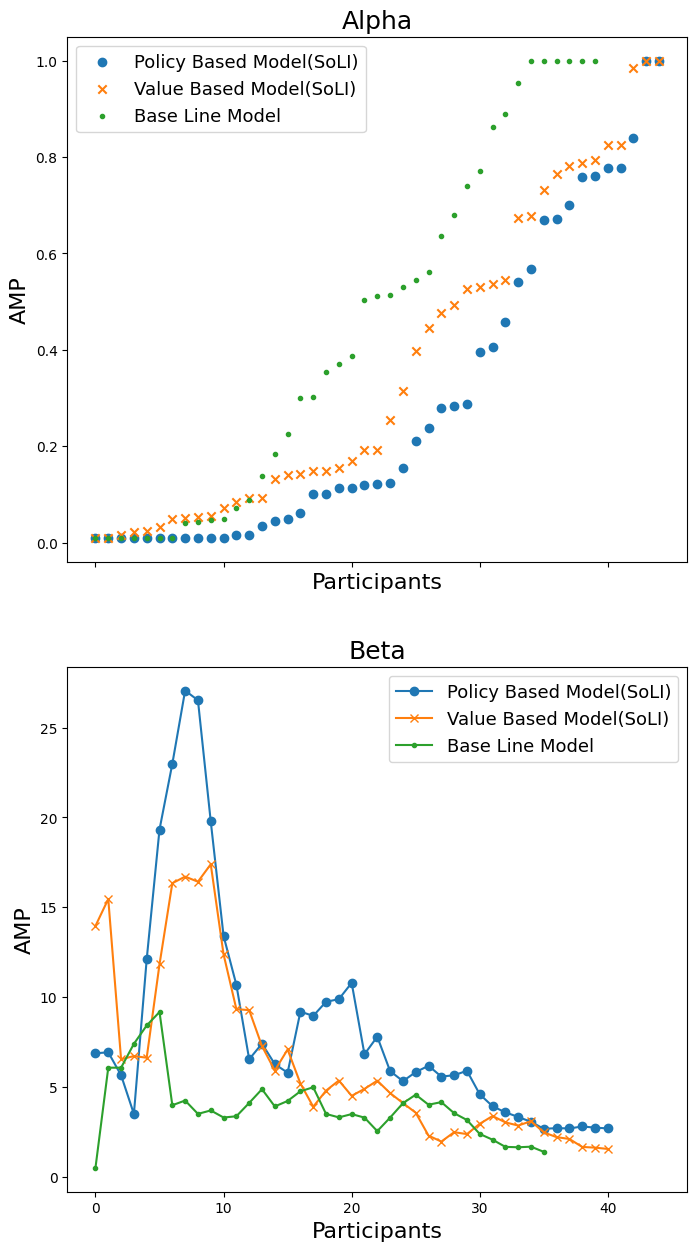

In [98]:
fig, axs = plt.subplots(2, 1, sharex='all', figsize=(8, 15))
x1 = [i for i in range(45)]
x2 = [i for i in range(40)]
axs[0].scatter(x1, np.sort(np.array(all_alpha_pQmean[:g1_len])), marker='o', label='Policy Based Model(SoLI)')
axs[0].scatter(x1, np.sort(np.array(all_alpha_Qmean[:g1_len])), marker='x', label='Value Based Model(SoLI)')
axs[0].scatter(x2, np.sort(np.array(all_bl_alpha)), marker='.', label='Base Line Model')
axs[0].set_xlabel('Participants', fontsize=16)
axs[0].set_ylabel('AMP', fontsize=16)
axs[0].set_title('Alpha', fontsize=18)
axs[0].legend(loc=2, prop={'size': 13})

axs[1].plot(np.convolve(np.array(all_beta_pQmean[:g1_len])[p_alpha_idx], np.ones(5)/5, mode='valid'), marker='o', label='Policy Based Model(SoLI)')
axs[1].plot(np.convolve(np.array(all_epsilon_Qmean[:g1_len])[v_alpha_idx], np.ones(5)/5, mode='valid'), marker='x', label='Value Based Model(SoLI)')
axs[1].plot(np.convolve(np.array(all_bl_epsilon)[b_alpha_idx], np.ones(5)/5, mode='valid'), marker='.', label='Base Line Model')
axs[1].set_xlabel('Participants', fontsize=16)
axs[1].set_ylabel('AMP', fontsize=16)
axs[1].set_title('Beta', fontsize=18)
axs[1].legend(loc=1, prop={'size': 13})
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/Second edition/ALpha-Beta2.svg')

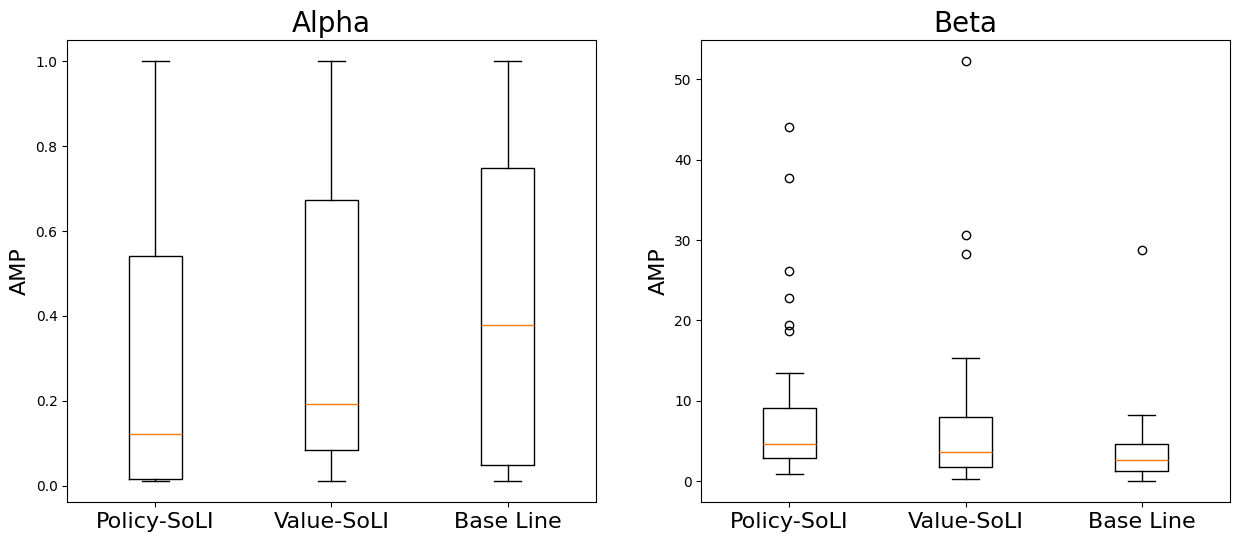

In [99]:

data1 = [np.array(all_alpha_pQmean[:g1_len]), np.array(all_alpha_Qmean[:g1_len]), np.array(all_bl_alpha)]
data2 = [np.array(all_beta_pQmean[:g1_len]), np.array(all_epsilon_Qmean[:g1_len]), np.array(all_bl_epsilon)]
ls = ['Policy-SoLI', 'Value-SoLI', 'Base Line']

fig, axs = plt.subplots(1, 2, figsize=(15, 6))

axs[0].boxplot(data1, labels=ls)
axs[0].set_xticklabels(ls, fontsize=16)
axs[0].set_ylabel('AMP', fontsize=16)
axs[0].set_title('Alpha', fontsize=20)

axs[1].boxplot(data2, labels=ls)
axs[1].set_xticklabels(ls, fontsize=16)
axs[1].set_ylabel('AMP', fontsize=16)
axs[1].set_title('Beta', fontsize=20)
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/Second edition/ALpha-Beta-bplot.svg')

Gamma

In [100]:
trained_pg_best_idx = np.argsort(sorted_pg_m[:g1_len, 0])

sorted_trained_pg_best = sorted_pg_m[:g1_len, 0][trained_pg_best_idx]
sorted_trained_pg_second = sorted_pg_m[:g1_len, 1][trained_pg_best_idx]
sorted_trained_pg_worst = sorted_pg_m[:g1_len, 2][trained_pg_best_idx]

In [101]:
trained_g_best_idx = np.argsort(sorted_g_m[:g1_len, 0])

sorted_trained_g_best = sorted_g_m[:g1_len, 0][trained_g_best_idx]
sorted_trained_g_second = sorted_g_m[:g1_len, 1][trained_g_best_idx]
sorted_trained_g_worst = sorted_g_m[:g1_len, 2][trained_g_best_idx]

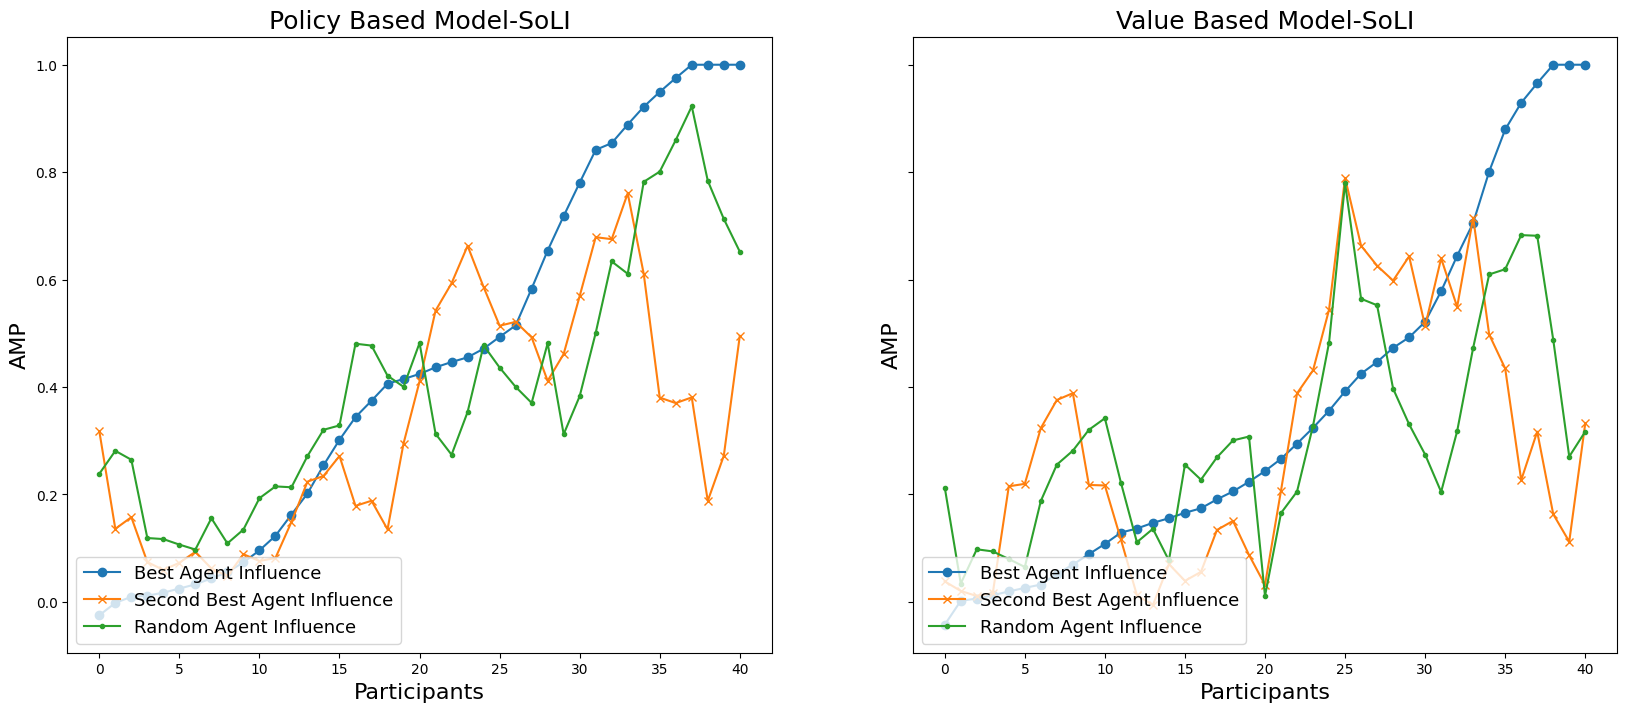

In [102]:
fig, axs = plt.subplots(1, 2, sharey='all', figsize=(20, 8))
x1 = [i for i in range(45)]


# np.convolve(sorted_trained_g_best, np.ones(3)/3, mode='valid')

axs[0].plot(np.convolve(sorted_trained_pg_best, np.ones(5)/5, mode='valid'), marker='o', label='Best Agent Influence')
axs[0].plot(np.convolve(sorted_trained_pg_second, np.ones(5)/5, mode='valid'), marker='x', label='Second Best Agent Influence')
axs[0].plot(np.convolve(sorted_trained_pg_worst, np.ones(5)/5, mode='valid'), marker='.', label='Random Agent Influence')
axs[0].set_title('Policy Based Model-SoLI', fontsize=18)
axs[0].set_xlabel('Participants', fontsize=16)
axs[0].set_ylabel('AMP', fontsize=16)
axs[0].legend(loc=3, prop={'size': 13})

axs[1].plot(np.convolve(sorted_trained_g_best, np.ones(5)/5, mode='valid'), marker='o', label='Best Agent Influence')
axs[1].plot(np.convolve(sorted_trained_g_second, np.ones(5)/5, mode='valid'), marker='x', label='Second Best Agent Influence')
axs[1].plot(np.convolve(sorted_trained_g_worst, np.ones(5)/5, mode='valid'), marker='.', label='Random Agent Influence')
axs[1].set_title('Value Based Model-SoLI', fontsize=18)
axs[1].set_xlabel('Participants', fontsize=16)
axs[1].set_ylabel('AMP', fontsize=16)
axs[1].legend(loc=3, prop={'size': 13})
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/Second edition/Gammas-1.svg')

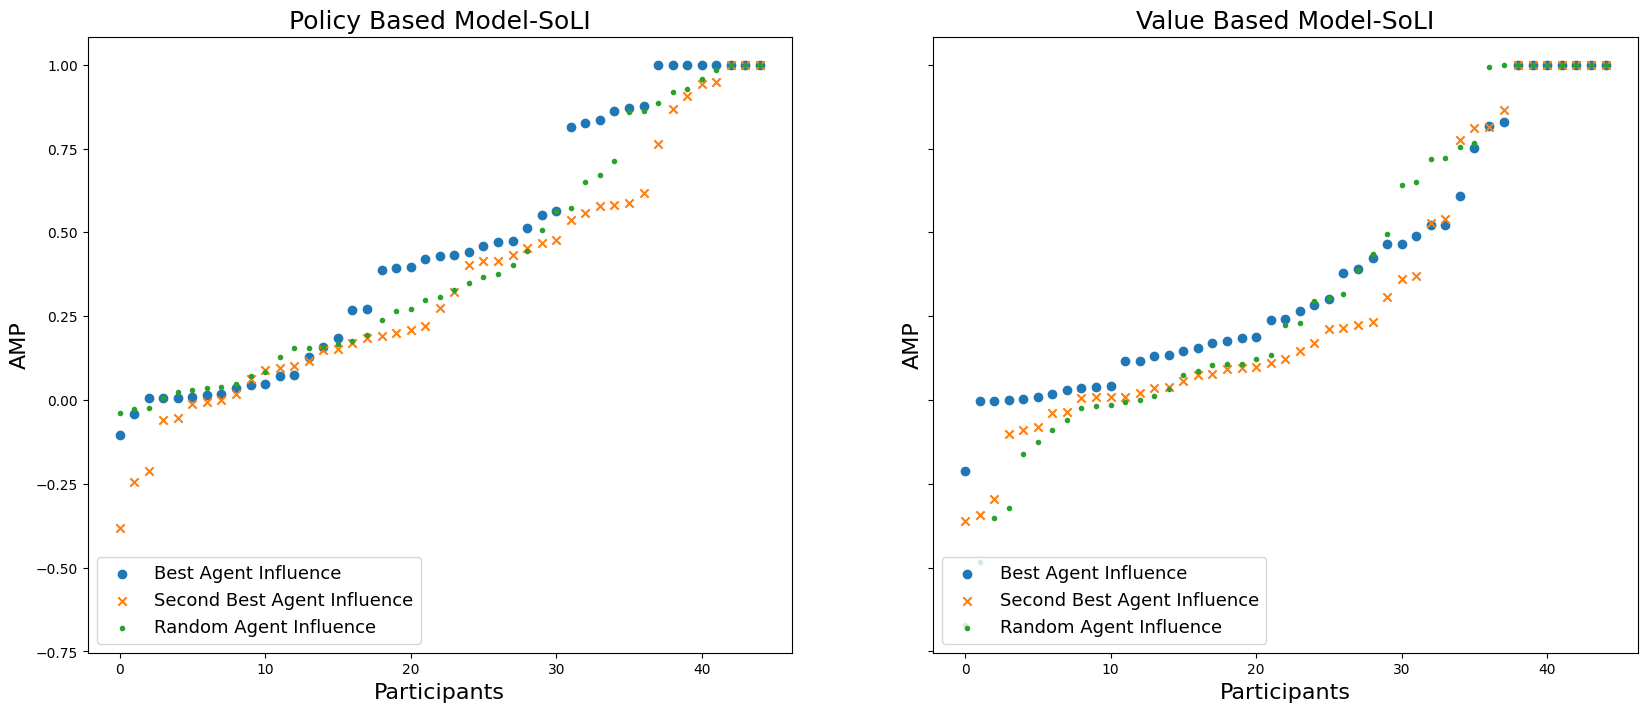

In [103]:
fig, axs = plt.subplots(1, 2, sharey='all', figsize=(20, 8))
x1 = [i for i in range(45)]
axs[0].scatter(x1, np.sort(sorted_pg_m[:g1_len, 0]), marker='o', label='Best Agent Influence')
axs[0].scatter(x1, np.sort(sorted_pg_m[:g1_len, 1]), marker='x', label='Second Best Agent Influence')
axs[0].scatter(x1, np.sort(sorted_pg_m[:g1_len, 2]), marker='.', label='Random Agent Influence')
axs[0].set_title('Policy Based Model-SoLI', fontsize=18)
axs[0].set_xlabel('Participants', fontsize=16)
axs[0].set_ylabel('AMP', fontsize=16)
axs[0].legend(loc=3, prop={'size': 13})

axs[1].scatter(x1, np.sort(sorted_g_m[:g1_len, 0]), marker='o', label='Best Agent Influence')
axs[1].scatter(x1, np.sort(sorted_g_m[:g1_len, 1]), marker='x', label='Second Best Agent Influence')
axs[1].scatter(x1, np.sort(sorted_g_m[:g1_len, 2]), marker='.', label='Random Agent Influence')
axs[1].set_title('Value Based Model-SoLI', fontsize=18)
axs[1].set_xlabel('Participants', fontsize=16)
axs[1].set_ylabel('AMP', fontsize=16)
axs[1].legend(loc=3, prop={'size': 13})
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/Second edition/Gammas-2.svg')

Gamma box plots

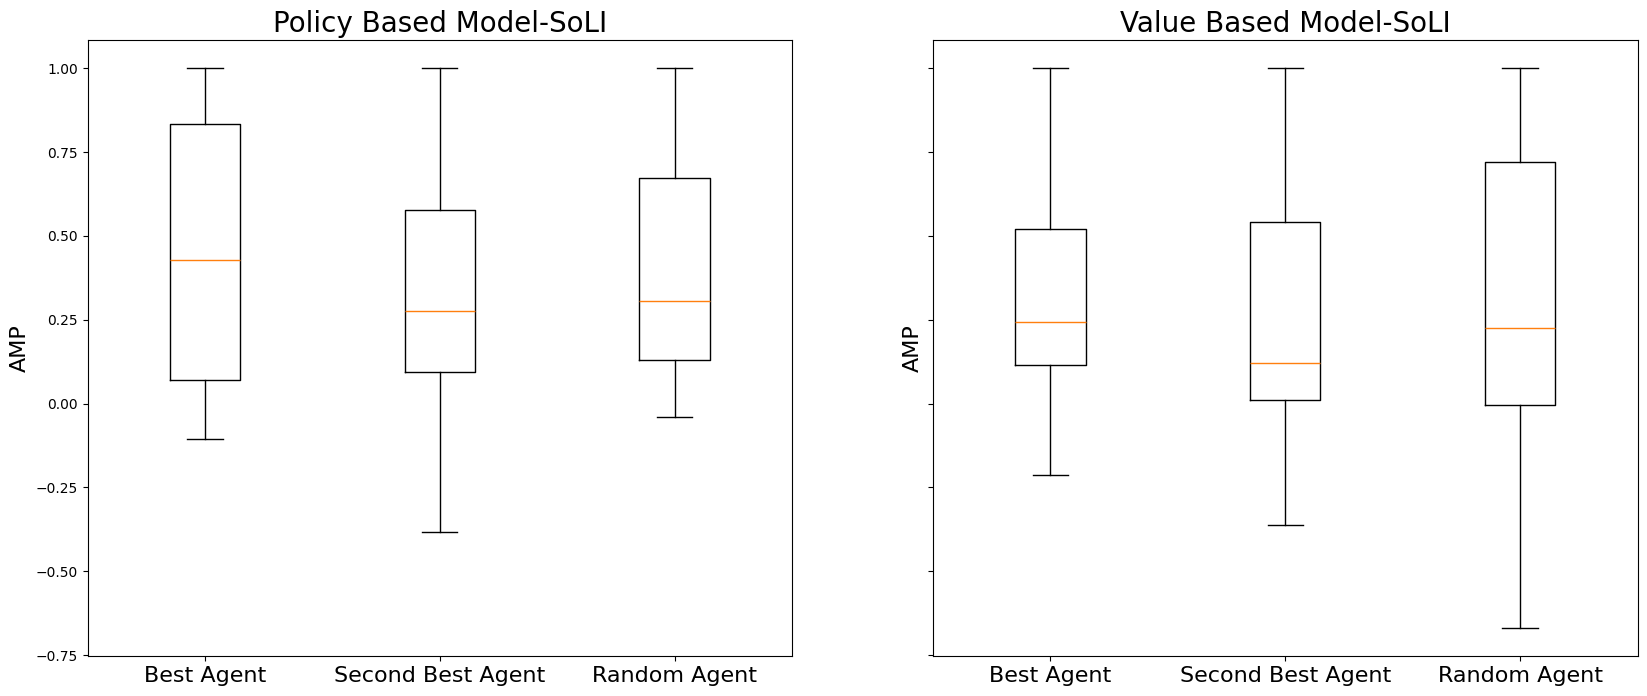

In [104]:
data1 = [sorted_pg_m[:g1_len, 0], sorted_pg_m[:g1_len, 1], sorted_pg_m[:g1_len, 2]]
data2 = [sorted_g_m[:g1_len, 0], sorted_g_m[:g1_len, 1], sorted_g_m[:g1_len, 2]]

fig, axs = plt.subplots(1, 2, sharey='all', figsize=(20, 8))
ls = ['Best Agent', 'Second Best Agent', 'Random Agent']
axs[0].boxplot(data1, labels=ls)
axs[0].set_xticklabels(ls, fontsize=16)
axs[0].set_ylabel('AMP', fontsize=16)
axs[0].set_title('Policy Based Model-SoLI', fontsize=20)

axs[1].boxplot(data2, labels=ls)
axs[1].set_xticklabels(ls, fontsize=16)
axs[1].set_ylabel('AMP', fontsize=16)
axs[1].set_title('Value Based Model-SoLI', fontsize=20)
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/Second edition/Gammas-bplot.svg')

# RL VIS LAST VERSION

## value based model data sorting (by beta)

SoLI

In [105]:
# sorted_numbers, indices = np.array(numbers)[np.argsort(numbers)], np.argsort(numbers)

v_sorted_beta_m, v_sorted_idx_m = np.array(all_epsilon_Qmean[:45])[np.argsort(all_epsilon_Qmean[:45])], np.argsort(all_epsilon_Qmean[:45])
v_sorted_alpha_m = np.array(all_alpha_Qmean[:45])[list(v_sorted_idx_m)]
v_sorted_best_m = sorted_g_m[:45, 0][list(v_sorted_idx_m)]
v_sorted_second_m = sorted_g_m[:45, 1][list(v_sorted_idx_m)]
v_sorted_worst_m = sorted_g_m[:45, 2][list(v_sorted_idx_m)]

SoLU

In [106]:
U_v_sorted_beta_m, U_v_sorted_idx_m = np.array(all_epsilon_Qmean[45:])[np.argsort(all_epsilon_Qmean[45:])], np.argsort(all_epsilon_Qmean[45:])
U_v_sorted_alpha_m = np.array(all_alpha_Qmean[45:])[list(U_v_sorted_idx_m)]
U_v_sorted_best_m = sorted_g_m[45:, 0][list(U_v_sorted_idx_m)]
U_v_sorted_second_m = sorted_g_m[45:, 1][list(U_v_sorted_idx_m)]
U_v_sorted_worst_m = sorted_g_m[45:, 2][list(U_v_sorted_idx_m)]

## Policy based model data sorting (by beta)

SoLI

In [107]:
p_sorted_beta_m, p_sorted_idx_m = np.array(all_beta_pQmean[:45])[np.argsort(all_beta_pQmean[:45])], np.argsort(all_beta_pQmean[:45])
p_sorted_alpha_m = np.array(all_alpha_pQmean[:45])[list(p_sorted_idx_m)]
p_sorted_best_m = sorted_pg_m[:45, 0][list(p_sorted_idx_m)]
p_sorted_second_m = sorted_pg_m[:45, 1][list(p_sorted_idx_m)]
p_sorted_worst_m = sorted_pg_m[:45, 2][list(p_sorted_idx_m)]

SoLU

In [108]:
U_p_sorted_beta_m, U_p_sorted_idx_m = np.array(all_beta_pQmean[45:])[np.argsort(all_beta_pQmean[45:])], np.argsort(all_beta_pQmean[45:])
U_p_sorted_alpha_m = np.array(all_alpha_pQmean[45:])[list(U_p_sorted_idx_m)]
U_p_sorted_best_m = sorted_pg_m[45:, 0][list(U_p_sorted_idx_m)]
U_p_sorted_second_m = sorted_pg_m[45:, 1][list(U_p_sorted_idx_m)]
U_p_sorted_worst_m = sorted_pg_m[45:, 2][list(U_p_sorted_idx_m)]

## Visualizing

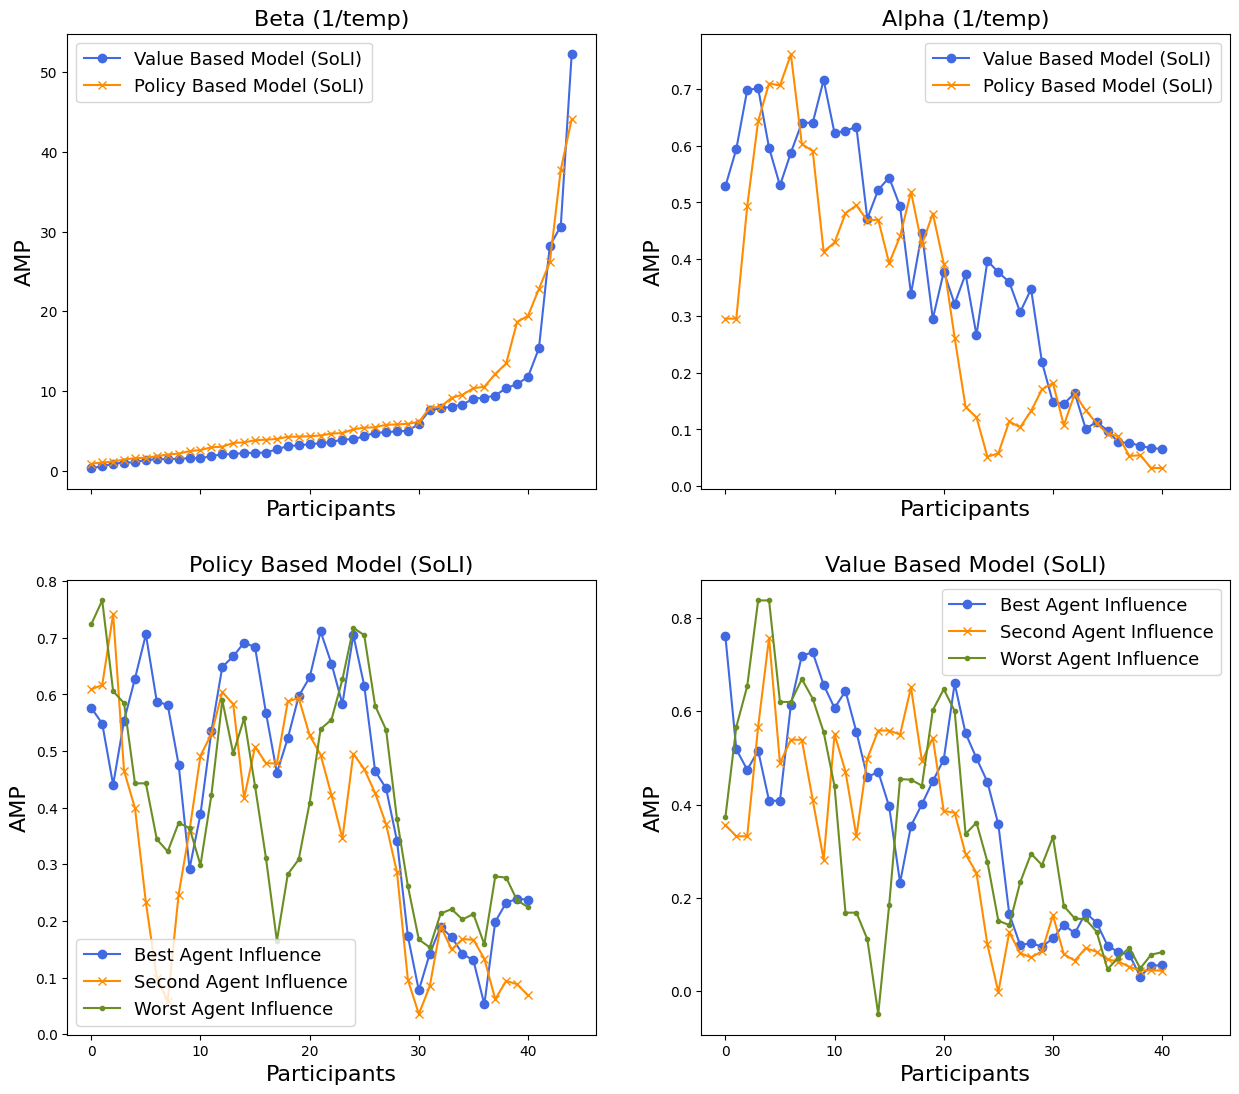

In [109]:
fig, axs = plt.subplots(2, 2, sharex='all', figsize=(15, 13))

x1 = [i for i in range(45)]

axs[0, 0].plot(v_sorted_beta_m, marker='o', label='Value Based Model (SoLI)', color='royalblue')
axs[0, 0].plot(p_sorted_beta_m, marker='x', label='Policy Based Model (SoLI)', color='darkorange')
# axs[0, 0].plot(U_v_sorted_beta_m, marker='o', label='Value Based Model (SoLI)', color='olivedrab')
# axs[0, 0].plot(U_p_sorted_beta_m, marker='x', label='Policy Based Model (SoLI)', color='firebrick')
axs[0, 0].set_title('Beta (1/temp)', fontsize=16)
axs[0, 0].set_xlabel('Participants', fontsize=16)
axs[0, 0].set_ylabel('AMP', fontsize=16)
axs[0, 0].legend(loc=0, prop={'size':13})

axs[0, 1].plot(np.convolve(v_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='o', label='Value Based Model (SoLI)', color='royalblue')
axs[0, 1].plot(np.convolve(p_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='x', label='Policy Based Model (SoLI)', color='darkorange')
axs[0, 1].set_title('Alpha (1/temp)', fontsize=16)
axs[0, 1].set_xlabel('Participants', fontsize=16)
axs[0, 1].set_ylabel('AMP', fontsize=16)
axs[0, 1].legend(loc=0, prop={'size':13})

axs[1, 0].plot(np.convolve(p_sorted_best_m, np.ones(5)/5, mode='valid'), marker='o', label='Best Agent Influence', color='royalblue')
axs[1, 0].plot(np.convolve(p_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent Influence', color='darkorange')
axs[1, 0].plot(np.convolve(p_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent Influence', color='olivedrab')
axs[1, 0].set_title('Policy Based Model (SoLI)', fontsize=16)
axs[1, 0].set_xlabel('Participants', fontsize=16)
axs[1, 0].set_ylabel('AMP', fontsize=16)
axs[1, 0].legend(loc=0, prop={'size':13})

axs[1, 1].plot(np.convolve(v_sorted_best_m, np.ones(5)/5, mode='valid'), marker='o', label='Best Agent Influence', color='royalblue')
axs[1, 1].plot(np.convolve(v_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent Influence', color='darkorange')
axs[1, 1].plot(np.convolve(v_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent Influence', color='olivedrab')
axs[1, 1].set_title('Value Based Model (SoLI)', fontsize=16)
axs[1, 1].set_xlabel('Participants', fontsize=16)
axs[1, 1].set_ylabel('AMP', fontsize=16)
axs[1, 1].legend(loc=0, prop={'size':13})
# np.convolve(p_sorted_best_m, np.ones(5)/5, mode='valid')

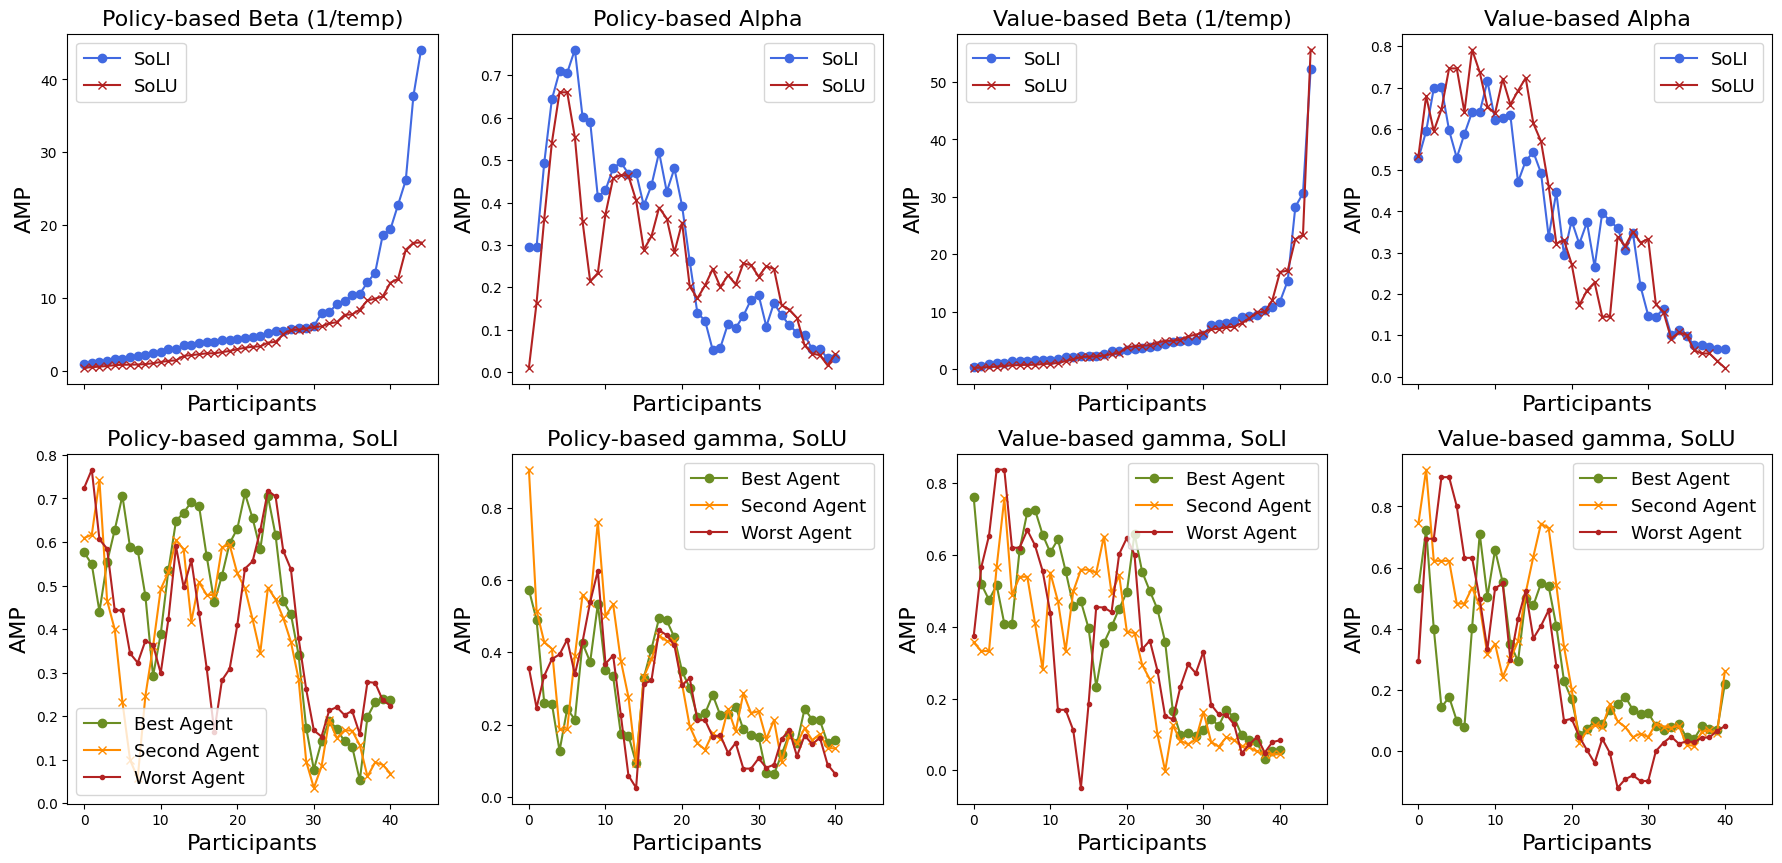

In [110]:
fig, axs = plt.subplots(2, 4, sharex='all', figsize=(22, 10))

x1 = [i for i in range(45)]
axs[0, 0].plot(p_sorted_beta_m, marker='o', label='SoLI', color='royalblue')
axs[0, 0].plot(U_p_sorted_beta_m, marker='x', label='SoLU', color='firebrick')
axs[0, 0].set_title('Policy-based Beta (1/temp)', fontsize=16)
axs[0, 0].set_xlabel('Participants', fontsize=16)
axs[0, 0].set_ylabel('AMP', fontsize=16)
axs[0, 0].legend(loc=0, prop={'size':13})

axs[0, 1].plot(np.convolve(p_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='o', label='SoLI', color='royalblue')
axs[0, 1].plot(np.convolve(U_p_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='x', label='SoLU', color='firebrick')
axs[0, 1].set_title('Policy-based Alpha', fontsize=16)
axs[0, 1].set_xlabel('Participants', fontsize=16)
axs[0, 1].set_ylabel('AMP', fontsize=16)
axs[0, 1].legend(loc=0, prop={'size':13})

axs[0, 2].plot(v_sorted_beta_m, marker='o', label='SoLI', color='royalblue')
axs[0, 2].plot(U_v_sorted_beta_m, marker='x', label='SoLU', color='firebrick')
axs[0, 2].set_title('Value-based Beta (1/temp)', fontsize=16)
axs[0, 2].set_xlabel('Participants', fontsize=16)
axs[0, 2].set_ylabel('AMP', fontsize=16)
axs[0, 2].legend(loc=0, prop={'size':13})

axs[0, 3].plot(np.convolve(v_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='o', label='SoLI', color='royalblue')
axs[0, 3].plot(np.convolve(U_v_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='x', label='SoLU', color='firebrick')
axs[0, 3].set_title('Value-based Alpha', fontsize=16)
axs[0, 3].set_xlabel('Participants', fontsize=16)
axs[0, 3].set_ylabel('AMP', fontsize=16)
axs[0, 3].legend(loc=0, prop={'size':13})

axs[1, 0].plot(np.convolve(p_sorted_best_m, np.ones(5)/5, mode='valid'), marker='o', label='Best Agent', color='olivedrab')
axs[1, 0].plot(np.convolve(p_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 0].plot(np.convolve(p_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 0].set_title('Policy-based gamma, SoLI', fontsize=16)
axs[1, 0].set_xlabel('Participants', fontsize=16)
axs[1, 0].set_ylabel('AMP', fontsize=16)
axs[1, 0].legend(loc=0, prop={'size':13})

axs[1, 1].plot(np.convolve(U_p_sorted_best_m, np.ones(5)/5, mode='valid'), marker='o', label='Best Agent', color='olivedrab')
axs[1, 1].plot(np.convolve(U_p_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 1].plot(np.convolve(U_p_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 1].set_title('Policy-based gamma, SoLU', fontsize=16)
axs[1, 1].set_xlabel('Participants', fontsize=16)
axs[1, 1].set_ylabel('AMP', fontsize=16)
axs[1, 1].legend(loc=0, prop={'size':13})

axs[1, 2].plot(np.convolve(v_sorted_best_m, np.ones(5)/5, mode='valid'), marker='o', label='Best Agent', color='olivedrab')
axs[1, 2].plot(np.convolve(v_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 2].plot(np.convolve(v_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 2].set_title('Value-based gamma, SoLI', fontsize=16)
axs[1, 2].set_xlabel('Participants', fontsize=16)
axs[1, 2].set_ylabel('AMP', fontsize=16)
axs[1, 2].legend(loc=0, prop={'size':13})

axs[1, 3].plot(np.convolve(U_v_sorted_best_m, np.ones(5)/5, mode='valid'), marker='o', label='Best Agent', color='olivedrab')
axs[1, 3].plot(np.convolve(U_v_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 3].plot(np.convolve(U_v_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 3].set_title('Value-based gamma, SoLU', fontsize=16)
axs[1, 3].set_xlabel('Participants', fontsize=16)
axs[1, 3].set_ylabel('AMP', fontsize=16)
axs[1, 3].legend(loc=0, prop={'size':13})


fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/newRL1.svg')

## Value based data sorting by best agent influence

SoLI

In [111]:
agv_sorted_best_m, agv_sorted_idx_m = sorted_g_m[:45, 0][np.argsort(sorted_g_m[:45, 0])], np.argsort(sorted_g_m[:45, 0])
agv_sorted_beta_m = np.array(all_epsilon_Qmean[:45])[list(agv_sorted_idx_m)]
agv_sorted_alpha_m = np.array(all_alpha_Qmean[:45])[list(agv_sorted_idx_m)]
agv_sorted_second_m = sorted_g_m[:45, 1][list(agv_sorted_idx_m)]
agv_sorted_worst_m = sorted_g_m[:45, 2][list(agv_sorted_idx_m)]

SoLU

In [112]:
U_agv_sorted_best_m, U_agv_sorted_idx_m = sorted_g_m[45:, 0][np.argsort(sorted_g_m[45:, 0])], np.argsort(sorted_g_m[45:, 0])
U_agv_sorted_beta_m = np.array(all_epsilon_Qmean[45:])[list(U_agv_sorted_idx_m)]
U_agv_sorted_alpha_m = np.array(all_alpha_Qmean[45:])[list(U_agv_sorted_idx_m)]
U_agv_sorted_second_m = sorted_g_m[45:, 1][list(U_agv_sorted_idx_m)]
U_agv_sorted_worst_m = sorted_g_m[45:, 2][list(U_agv_sorted_idx_m)]

## Policy based data sorting by best agent influence

SoLI

In [113]:
agp_sorted_best_m, agp_sorted_idx_m = sorted_pg_m[:45, 0][np.argsort(sorted_pg_m[:45, 0])], np.argsort(sorted_pg_m[:45, 0])
agp_sorted_beta_m = np.array(all_beta_pQmean[:45])[list(agp_sorted_idx_m)]
agp_sorted_alpha_m = np.array(all_alpha_pQmean[:45])[list(agp_sorted_idx_m)]
agp_sorted_second_m = sorted_pg_m[:45, 1][list(agp_sorted_idx_m)]
agp_sorted_worst_m = sorted_pg_m[:45, 2][list(agp_sorted_idx_m)]

SoLU

In [114]:
U_agp_sorted_best_m, U_agp_sorted_idx_m = sorted_pg_m[45:, 0][np.argsort(sorted_pg_m[45:, 0])], np.argsort(sorted_pg_m[45:, 0])
U_agp_sorted_beta_m = np.array(all_beta_pQmean[45:])[list(U_agp_sorted_idx_m)]
U_agp_sorted_alpha_m = np.array(all_alpha_pQmean[45:])[list(U_agp_sorted_idx_m)]
U_agp_sorted_second_m = sorted_pg_m[45:, 1][list(U_agp_sorted_idx_m)]
U_agp_sorted_worst_m = sorted_pg_m[45:, 2][list(U_agp_sorted_idx_m)]

## Visualizing

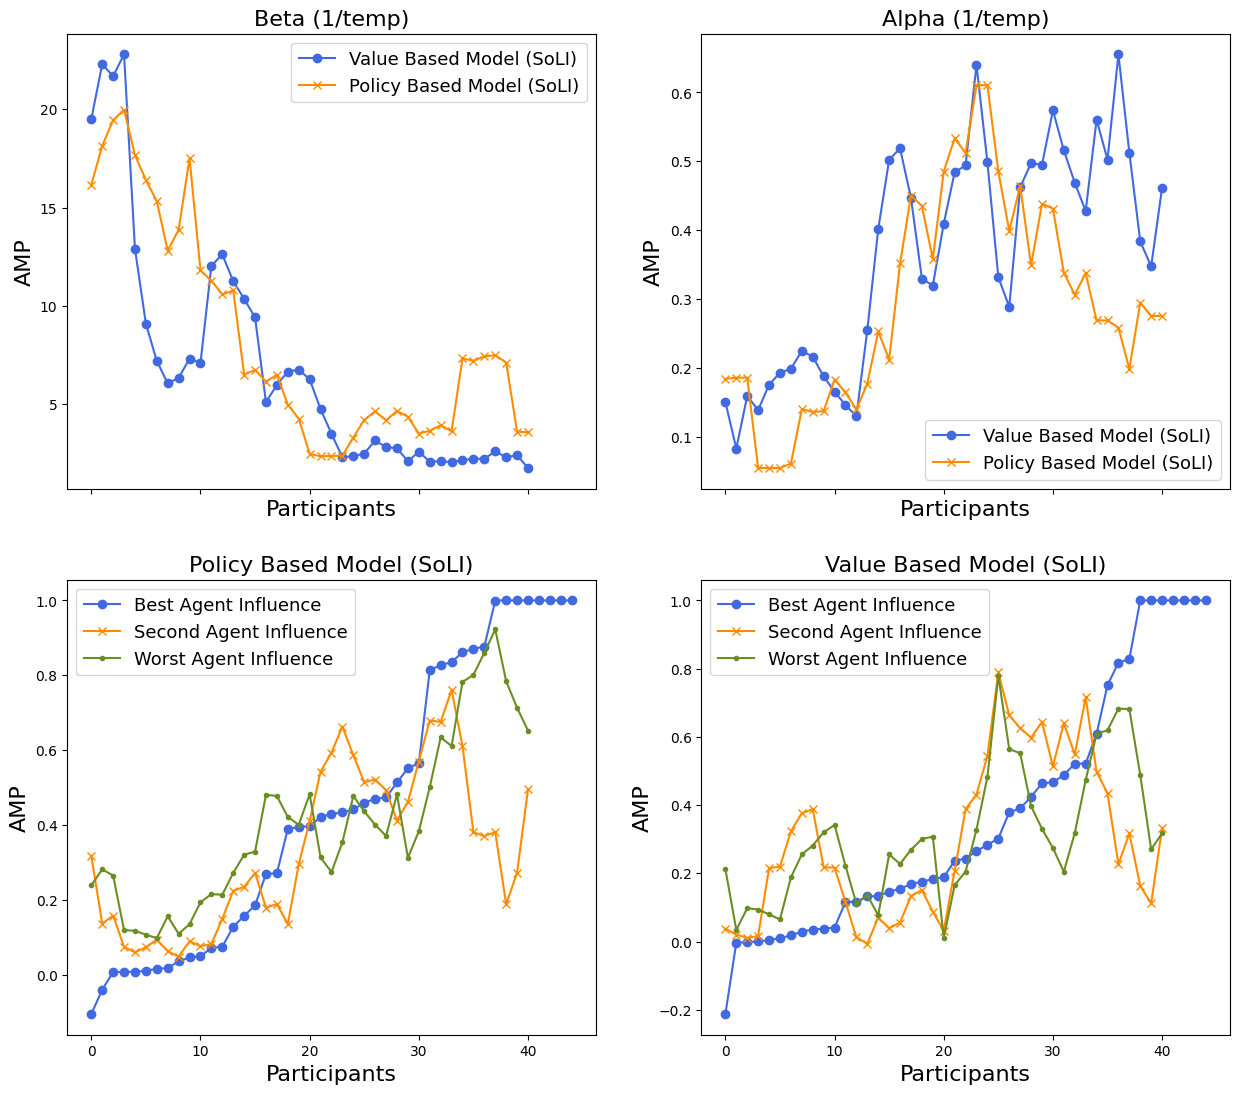

In [115]:
fig, axs = plt.subplots(2, 2, sharex='all', figsize=(15, 13))

x1 = [i for i in range(45)]

axs[0, 0].plot(np.convolve(agv_sorted_beta_m, np.ones(5)/5, mode='valid'), marker='o', label='Value Based Model (SoLI)', color='royalblue')
axs[0, 0].plot(np.convolve(agp_sorted_beta_m, np.ones(5)/5, mode='valid'), marker='x', label='Policy Based Model (SoLI)', color='darkorange')
axs[0, 0].set_title('Beta (1/temp)', fontsize=16)
axs[0, 0].set_xlabel('Participants', fontsize=16)
axs[0, 0].set_ylabel('AMP', fontsize=16)
axs[0, 0].legend(loc=0, prop={'size':13})

axs[0, 1].plot(np.convolve(agv_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='o', label='Value Based Model (SoLI)', color='royalblue')
axs[0, 1].plot(np.convolve(agp_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='x', label='Policy Based Model (SoLI)', color='darkorange')
axs[0, 1].set_title('Alpha (1/temp)', fontsize=16)
axs[0, 1].set_xlabel('Participants', fontsize=16)
axs[0, 1].set_ylabel('AMP', fontsize=16)
axs[0, 1].legend(loc=0, prop={'size':13})

axs[1, 0].plot(agp_sorted_best_m, marker='o', label='Best Agent Influence', color='royalblue')
axs[1, 0].plot(np.convolve(agp_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent Influence', color='darkorange')
axs[1, 0].plot(np.convolve(agp_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent Influence', color='olivedrab')
axs[1, 0].set_title('Policy Based Model (SoLI)', fontsize=16)
axs[1, 0].set_xlabel('Participants', fontsize=16)
axs[1, 0].set_ylabel('AMP', fontsize=16)
axs[1, 0].legend(loc=0, prop={'size':13})

axs[1, 1].plot(agv_sorted_best_m, marker='o', label='Best Agent Influence', color='royalblue')
axs[1, 1].plot(np.convolve(agv_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent Influence', color='darkorange')
axs[1, 1].plot(np.convolve(agv_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent Influence', color='olivedrab')
axs[1, 1].set_title('Value Based Model (SoLI)', fontsize=16)
axs[1, 1].set_xlabel('Participants', fontsize=16)
axs[1, 1].set_ylabel('AMP', fontsize=16)
axs[1, 1].legend(loc=0, prop={'size':13})

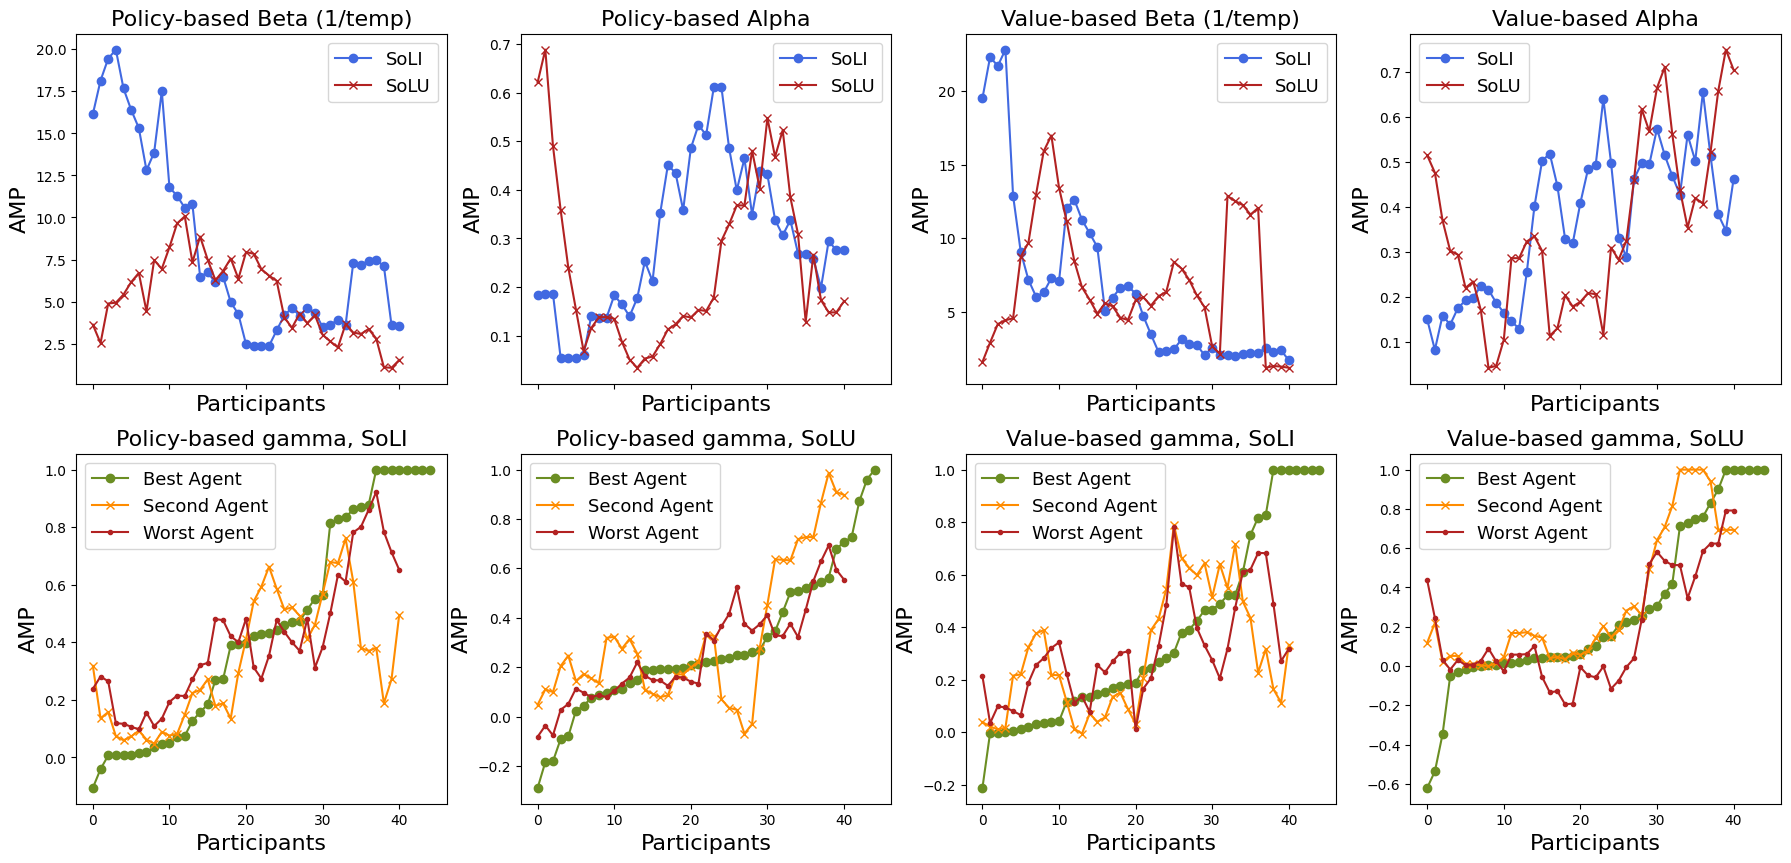

In [116]:
fig, axs = plt.subplots(2, 4, sharex='all', figsize=(22, 10))

x1 = [i for i in range(45)]




axs[0, 0].plot(np.convolve(agp_sorted_beta_m, np.ones(5)/5, mode='valid'), marker='o', label='SoLI', color='royalblue')
axs[0, 0].plot(np.convolve(U_agp_sorted_beta_m, np.ones(5)/5, mode='valid'), marker='x', label='SoLU', color='firebrick')
axs[0, 0].set_title('Policy-based Beta (1/temp)', fontsize=16)
axs[0, 0].set_xlabel('Participants', fontsize=16)
axs[0, 0].set_ylabel('AMP', fontsize=16)
axs[0, 0].legend(loc=0, prop={'size':13})

axs[0, 1].plot(np.convolve(agp_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='o', label='SoLI', color='royalblue')
axs[0, 1].plot(np.convolve(U_agp_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='x', label='SoLU', color='firebrick')
axs[0, 1].set_title('Policy-based Alpha', fontsize=16)
axs[0, 1].set_xlabel('Participants', fontsize=16)
axs[0, 1].set_ylabel('AMP', fontsize=16)
axs[0, 1].legend(loc=0, prop={'size':13})

axs[0, 2].plot(np.convolve(agv_sorted_beta_m, np.ones(5)/5, mode='valid'), marker='o', label='SoLI', color='royalblue')
axs[0, 2].plot(np.convolve(U_agv_sorted_beta_m, np.ones(5)/5, mode='valid'), marker='x', label='SoLU', color='firebrick')
axs[0, 2].set_title('Value-based Beta (1/temp)', fontsize=16)
axs[0, 2].set_xlabel('Participants', fontsize=16)
axs[0, 2].set_ylabel('AMP', fontsize=16)
axs[0, 2].legend(loc=0, prop={'size':13})

axs[0, 3].plot(np.convolve(agv_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='o', label='SoLI', color='royalblue')
axs[0, 3].plot(np.convolve(U_agv_sorted_alpha_m, np.ones(5)/5, mode='valid'), marker='x', label='SoLU', color='firebrick')
axs[0, 3].set_title('Value-based Alpha', fontsize=16)
axs[0, 3].set_xlabel('Participants', fontsize=16)
axs[0, 3].set_ylabel('AMP', fontsize=16)
axs[0, 3].legend(loc=0, prop={'size':13})

axs[1, 0].plot(agp_sorted_best_m, marker='o', label='Best Agent', color='olivedrab')
axs[1, 0].plot(np.convolve(agp_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 0].plot(np.convolve(agp_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 0].set_title('Policy-based gamma, SoLI', fontsize=16)
axs[1, 0].set_xlabel('Participants', fontsize=16)
axs[1, 0].set_ylabel('AMP', fontsize=16)
axs[1, 0].legend(loc=0, prop={'size':13})

axs[1, 1].plot(U_agp_sorted_best_m, marker='o', label='Best Agent', color='olivedrab')
axs[1, 1].plot(np.convolve(U_agp_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 1].plot(np.convolve(U_agp_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 1].set_title('Policy-based gamma, SoLU', fontsize=16)
axs[1, 1].set_xlabel('Participants', fontsize=16)
axs[1, 1].set_ylabel('AMP', fontsize=16)
axs[1, 1].legend(loc=0, prop={'size':13})

axs[1, 2].plot(agv_sorted_best_m, marker='o', label='Best Agent', color='olivedrab')
axs[1, 2].plot(np.convolve(agv_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 2].plot(np.convolve(agv_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 2].set_title('Value-based gamma, SoLI', fontsize=16)
axs[1, 2].set_xlabel('Participants', fontsize=16)
axs[1, 2].set_ylabel('AMP', fontsize=16)
axs[1, 2].legend(loc=0, prop={'size':13})

axs[1, 3].plot(U_agv_sorted_best_m, marker='o', label='Best Agent', color='olivedrab')
axs[1, 3].plot(np.convolve(U_agv_sorted_second_m, np.ones(5)/5, mode='valid'), marker='x', label='Second Agent', color='darkorange')
axs[1, 3].plot(np.convolve(U_agv_sorted_worst_m, np.ones(5)/5, mode='valid'), marker='.', label='Worst Agent', color='firebrick')
axs[1, 3].set_title('Value-based gamma, SoLU', fontsize=16)
axs[1, 3].set_xlabel('Participants', fontsize=16)
axs[1, 3].set_ylabel('AMP', fontsize=16)
axs[1, 3].legend(loc=0, prop={'size':13})

fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/main/paper draft/Figures/newRL2.svg')

# Clustering

Performance

In [91]:
def perf_perc(sub_df):
    all_sub_b1_perf = []
    all_sub_b2_perf = []
    all_sub_b3_perf = []
    for sub in sub_df:
        b1_bc_count = 0
        b2_bc_count = 0
        b3_bc_count = 0
        for trial in range(0, 15):
            ch = sub['choice'][trial]
            card_probs = eval(sub['card probs'][trial])
            if ch == card_probs.index(0.7):
                b1_bc_count += 1
        all_sub_b1_perf.append(b1_bc_count/15)
        for trial in range(15, 45):
            ch = sub['choice'][trial]
            card_probs = eval(sub['card probs'][trial])
            if ch == card_probs.index(0.7):
                b2_bc_count += 1
        all_sub_b2_perf.append(b2_bc_count/30)
        for trial in range(45, 105):
            ch = sub['choice'][trial]
            card_probs = eval(sub['card probs'][trial])
            if ch == card_probs.index(0.7):
                b3_bc_count += 1
        all_sub_b3_perf.append(b3_bc_count/60)   
    return all_sub_b1_perf, all_sub_b2_perf, all_sub_b3_perf

In [92]:
def perff_2arm(sub_df):
    perf = []
    for idx, sub in enumerate(sub_df):
        bc_count = 0
        card_probs = eval(sub['probs'][0])
        bc_idx = card_probs.index(0.8)
        for trial in range(30):
            ch = sub['choice'][trial]
            if ch == bc_idx:
                bc_count += 1
        perf.append(bc_count/30)
    return perf

In [93]:
soli_b1_perf, soli_b2_perf, soli_b3_perf = perf_perc(all_trained_4arm_df)
soli_2arm_perf = perff_2arm(all_trained_2arm_df)

In [94]:
soli_b1_perf = np.array(soli_b1_perf)
soli_b2_perf = np.array(soli_b2_perf)
soli_b3_perf = np.array(soli_b3_perf)
soli_2arm_perf = np.array(soli_2arm_perf)

In [95]:
all_df = all_trained_4arm_df
b1_perf = soli_b1_perf
b2_perf = soli_b2_perf
b3_perf = soli_b3_perf
perf_2arm = soli_2arm_perf

In [96]:
def imitation_check(sub_df, start_trial, end_trial):
    sub_one_imit = 0
    sub_all_imit = 0
    ag_choice = 'x'
    for trial in range(start_trial, end_trial):
        sub_choice = sub_df['choice'][trial]
        if trial % 3 == 0:
            try:
                ag_choice = eval(sub_df['agent_choices'][trial])
            except:
                ag_choice = 100
            if sub_choice == ag_choice:
                sub_one_imit += 1
            
        if sub_choice == ag_choice:
            sub_all_imit += 1
    return sub_one_imit, sub_all_imit

In [97]:
joint_one_imit = []
joint_all_imit = []
for sub in all_df:
    one_imit, all_imit = imitation_check(sub, 45, 105)
    joint_one_imit.append(one_imit)
    joint_all_imit.append(all_imit)
    
joint_one_imit = np.array(joint_one_imit)
joint_all_imit = np.array(joint_all_imit)

Z Scoring

In [98]:
from scipy.stats import zscore

z_norm_b1_perf = zscore(b1_perf)
z_norm_b2_perf = zscore(b2_perf)
z_norm_b3_perf = zscore(b3_perf)
z_norm_2arm_perf = zscore(perf_2arm)

In [99]:
X = np.column_stack((z_norm_2arm_perf, z_norm_b1_perf, z_norm_b2_perf, z_norm_b3_perf))

In [100]:
Y = np.column_stack((perf_2arm, b1_perf, b2_perf, b3_perf))

In [101]:
from sklearn.cluster import AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

agg_clustering = AgglomerativeClustering(n_clusters=3)
y_pred = agg_clustering.fit_predict(X)

In [102]:
labels = agg_clustering.labels_

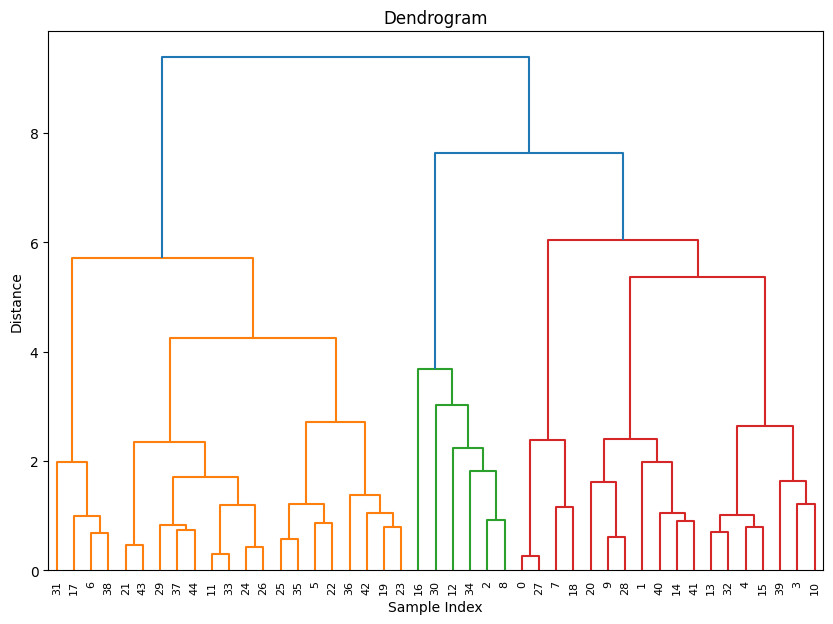

FileNotFoundError: [Errno 2] No such file or directory: 'D:/University/University of Tehran/MSc/Thesis/paper draft/Figures/Dendogram.svg'

In [103]:
Z = linkage(X, method='ward')

fig = plt.figure(figsize=(10, 7))
dendrogram(Z)
plt.title('Dendrogram')
plt.xlabel('Sample Index')
plt.ylabel('Distance')
plt.show()

fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/Figures/Dendogram.svg')

In [104]:
c1_all_imit = []
c1_one_imit = []
c2_all_imit = []
c2_one_imit = []
c3_all_imit = []
c3_one_imit = []
for idx, sub_cluster in enumerate(labels):
    if sub_cluster == 0:
        c1_all_imit.append(joint_all_imit[idx])
        c1_one_imit.append(joint_one_imit[idx])
    elif sub_cluster == 1:
        c2_all_imit.append(joint_all_imit[idx])
        c2_one_imit.append(joint_one_imit[idx])
    else:
        c3_all_imit.append(joint_all_imit[idx])
        c3_one_imit.append(joint_one_imit[idx])

Text(0.5, 1.0, 'All imitation')

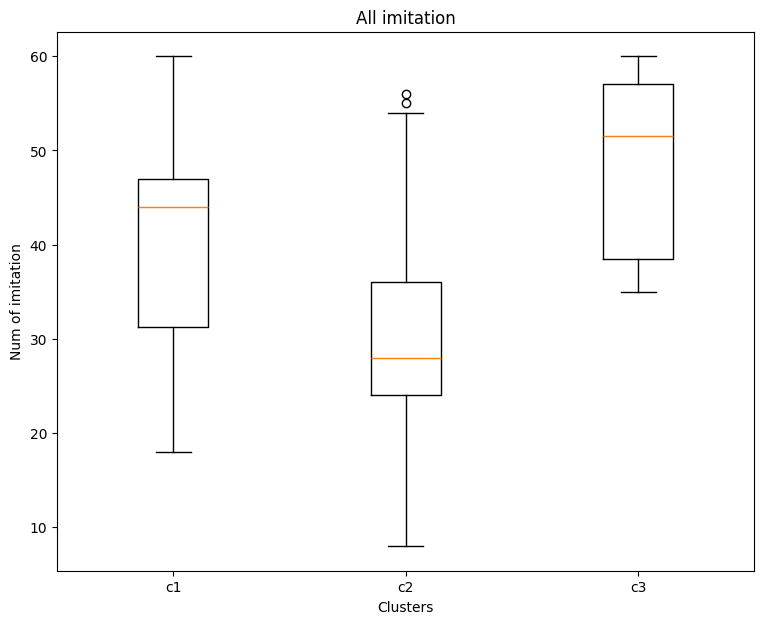

In [105]:
data1 = [c1_all_imit, c2_all_imit, c3_all_imit]
# data2 = [c1_one_imit, c2_one_imit, c3_one_imit]
cluster_labels = ['c1', 'c2', 'c3']


fig, axs = plt.subplots(1, 1, figsize=(9, 7))

# fig.suptitle('Entire block imitation')
axs.boxplot(data1)
# axs[1].boxplot(data2)

axs.set_xticklabels(cluster_labels)
# axs[1].set_xticklabels(cluster_labels)
axs.set_xlabel('Clusters')
axs.set_ylabel('Num of imitation')
# axs[1].set_xlabel('Clusters')
# axs[1].set_ylabel('Num of imitation')

axs.set_title('All imitation')
# axs[1].set_title('One imitation')

C:\Users\AsusIran\AppData\Local\Temp\ipykernel_22660\3975629373.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


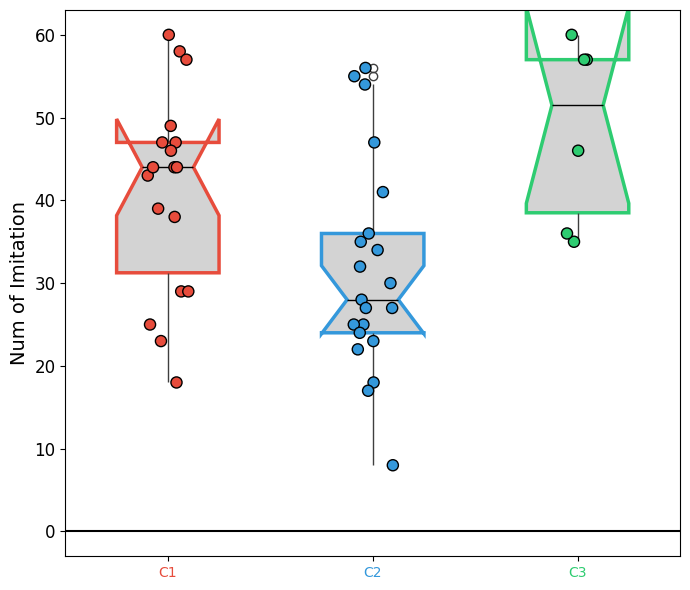

FileNotFoundError: [Errno 2] No such file or directory: 'D:/University/University of Tehran/MSc/Thesis/paper draft/Figures/Clustering.svg'

In [106]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Sample Data (Replace with your actual lists)
data1 = [c1_all_imit, c2_all_imit, c3_all_imit]
cluster_labels = ['C1', 'C2', 'C3']
colors = {'C1': '#E74C3C', 'C2': '#3498DB', 'C3': '#2ECC71'}  # Red, Blue, Green

# Convert data to long-form DataFrame
df = pd.DataFrame({
    'Clusters': sum([[cluster_labels[i]] * len(data1[i]) for i in range(3)], []),
    'Num of Imitation': sum(data1, [])
})

# Create the figure
fig = plt.figure(figsize=(7, 6))

# Boxplot with grey fill
boxplot = sns.boxplot(
    x='Clusters', y='Num of Imitation', data=df, 
    notch=True, width=0.5, showcaps=False,
    boxprops={'facecolor': 'lightgrey'},  # Initially set fill color
    medianprops={'color': 'black'}
)

# Manually set the edge color of each box
for i, artist in enumerate(boxplot.patches[:3]):  # Only first 3 are box bodies
    artist.set_edgecolor(colors[cluster_labels[i]])  # Set edge color
    artist.set_linewidth(2.5)  # Increase edge thickness

# Overlay a strip plot (Scatter points)
sns.stripplot(
    x='Clusters', y='Num of Imitation', data=df, 
    jitter=True, size=8, edgecolor='black', linewidth=1, 
    palette=[colors[c] for c in df['Clusters'].unique()]
)

# Add a horizontal reference line at 0
plt.axhline(0, color='black', linewidth=1.5)

# Set tick label colors
for tick, c in zip(plt.gca().get_xticklabels(), cluster_labels):
    tick.set_color(colors[c])

# Customizing the labels & title
plt.yticks(fontsize=12)
plt.ylabel('Num of Imitation', fontsize=14)
plt.xlabel('')
# plt.title('All Imitation', fontsize=16, fontweight='bold')

# P-value annotation
# plt.annotate(r'$P = 0.003$', xy=(1, max(df['Num of Imitation']) * 0.9), 
#              fontsize=14, fontstyle='italic', ha='center')

plt.tight_layout()
plt.show()
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/Figures/Clustering.svg')

gamma 

In [107]:
all_gamma = np.loadtxt('D:/University/University of Tehran/MSc/Thesis/task/Analysis/pgqm.txt')
trained_gamma = all_gamma[:45, :]
not_trained_gamma = all_gamma[45:, :]

In [108]:
c1_gamma = []
c2_gamma = []
c3_gamma = []

for idx, gm in enumerate(trained_gamma):
    if labels[idx] == 0:
        c1_gamma.append(gm)
    elif labels[idx] == 1:
        c2_gamma.append(gm)
    else:
        c3_gamma.append(gm)
        
c1_gamma = np.array(c1_gamma)
c2_gamma = np.array(c2_gamma)
c3_gamma = np.array(c3_gamma)

C:\Users\AsusIran\AppData\Local\Temp\ipykernel_22660\2204926194.py:36: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
C:\Users\AsusIran\AppData\Local\Temp\ipykernel_22660\2204926194.py:53: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(
C:\Users\AsusIran\AppData\Local\Temp\ipykernel_22660\2204926194.py:70: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.stripplot(


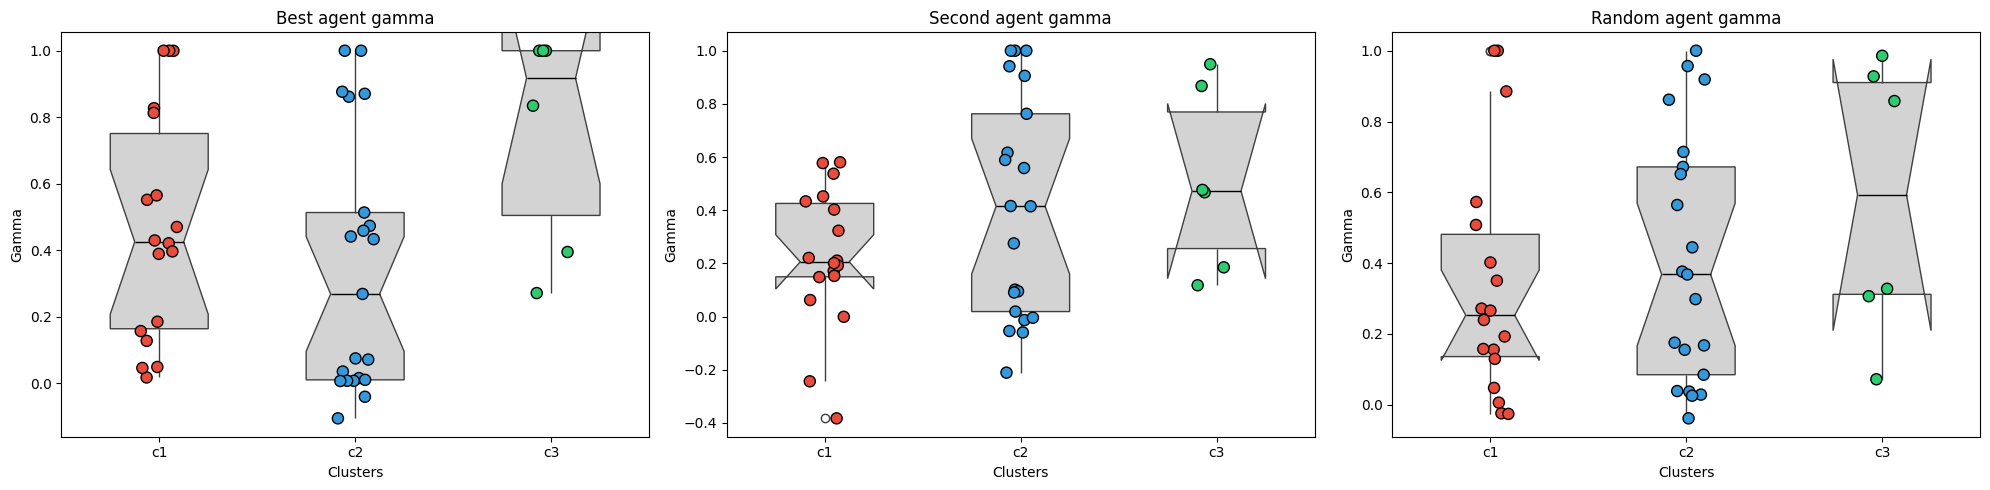

FileNotFoundError: [Errno 2] No such file or directory: 'D:/University/University of Tehran/MSc/Thesis/paper draft/Figures/G-Clustering.svg'

In [109]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Sample data (replace with your actual arrays)
data1 = [c1_gamma[:, 0], c2_gamma[:, 0], c3_gamma[:, 0]]
data2 = [c1_gamma[:, 1], c2_gamma[:, 1], c3_gamma[:, 1]]
data3 = [c1_gamma[:, 2], c2_gamma[:, 2], c3_gamma[:, 2]]
cluster_labels = ['c1', 'c2', 'c3']
colors = {'c1': '#E74C3C', 'c2': '#3498DB', 'c3': '#2ECC71'}

# Create the figure with subplots
fig, axs = plt.subplots(1, 3, figsize=(20, 5))
# fig.suptitle('SoLU Gammas for each cluster', fontsize=16)

# Concatenate the data using numpy
def create_df(data, cluster_labels):
    concatenated_data = np.concatenate(data)  # Concatenate the lists
    clusters = np.concatenate([[cluster_labels[i]] * len(data[i]) for i in range(len(data))])
    return pd.DataFrame({'Clusters': clusters, 'Gamma': concatenated_data})

# Create DataFrames for each gamma set
df1 = create_df(data1, cluster_labels)
df2 = create_df(data2, cluster_labels)
df3 = create_df(data3, cluster_labels)

# First subplot (Best agent gamma)
sns.boxplot(
    x='Clusters', y='Gamma', data=df1,
    notch=True, width=0.5, showcaps=False,
    boxprops={'facecolor': 'lightgrey'},  # Grey fill color for the boxes
    medianprops={'color': 'black'}, ax=axs[0]
)
# Overlay strip plot
sns.stripplot(
    x='Clusters', y='Gamma', data=df1,
    jitter=True, size=8, edgecolor='black', linewidth=1,
    palette=[colors[c] for c in cluster_labels], ax=axs[0]
)
axs[0].set_title('Best agent gamma')
axs[0].set_xlabel('Clusters')
axs[0].set_ylabel('Gamma')

# Second subplot (Second agent gamma)
sns.boxplot(
    x='Clusters', y='Gamma', data=df2,
    notch=True, width=0.5, showcaps=False,
    boxprops={'facecolor': 'lightgrey'},  # Grey fill color for the boxes
    medianprops={'color': 'black'}, ax=axs[1]
)
# Overlay strip plot
sns.stripplot(
    x='Clusters', y='Gamma', data=df2,
    jitter=True, size=8, edgecolor='black', linewidth=1,
    palette=[colors[c] for c in cluster_labels], ax=axs[1]
)
axs[1].set_title('Second agent gamma')
axs[1].set_xlabel('Clusters')
axs[1].set_ylabel('Gamma')

# Third subplot (Random agent gamma)
sns.boxplot(
    x='Clusters', y='Gamma', data=df3,
    notch=True, width=0.5, showcaps=False,
    boxprops={'facecolor': 'lightgrey'},  # Grey fill color for the boxes
    medianprops={'color': 'black'}, ax=axs[2]
)
# Overlay strip plot
sns.stripplot(
    x='Clusters', y='Gamma', data=df3,
    jitter=True, size=8, edgecolor='black', linewidth=1,
    palette=[colors[c] for c in cluster_labels], ax=axs[2]
)
axs[2].set_title('Random agent gamma')
axs[2].set_xlabel('Clusters')
axs[2].set_ylabel('Gamma')

# Adjust layout
plt.tight_layout()

# Show the plot
plt.show()
fig.savefig('D:/University/University of Tehran/MSc/Thesis/paper draft/Figures/G-Clustering.svg')